# SmokeGuard: Smoke Detection from the BME680 + PMS5003 Sensor Stream

SmokeGuard is a research prototype that recognises smoking activity from two complementary sensing streams: Wi-Fi Channel State Information (CSI) and an air-quality sensor stream. This notebook implements the **smoke-sensor model**: a binary classifier that decides whether a sensor window contains smoking activity.

The classifier is a **soft-margin Support Vector Machine with an RBF kernel**. Real-world sensor readings are noisy, so the soft-margin formulation tolerates misclassifications (slack variables `xi_i` traded against the margin by `C`). The decision function is calibrated with **Platt scaling**, producing `P(smoke | x) in [0, 1]` rather than a bare distance:

- The calibrated probability is the input the SmokeGuard late-fusion layer expects: `p_final = w1 * p_CSI + w2 * p_smoke`, with the weights and decision threshold tuned on validation data.
- Platt parameters `A` and `B` are recorded in the model metadata so the thesis formulation `P(smoke | x) = 1 / (1 + exp(A * d + B))` is materialised.

Key conventions, mirroring the CSI notebook:

- **Window length is derived from the data**, not hard-coded: `WINDOW_SECONDS` is the mean duration of the training intervals, computed once and frozen in the file split.
- **File-based holdout**: `TEST_ANNOTATION_FILES` names the held-out recording (currently `TEST_DATA.csv`). Every other observation CSV in the timestamps folder is training data. There is no validation split; the standalone threshold is tuned on grouped out-of-fold training predictions.
- **Grouped cross-validation**: intervals from one recording stay in one fold, so hyperparameter selection and threshold tuning measure cross-recording generalisation.
- **Provenance fingerprint**: if the split, labels, features, or model configuration change, the previous checkpoint is archived and the model is retrained; otherwise training is skipped.
- Models, splits, and training logs are persisted on Google Drive.

Sections:

1. **Environment setup** — Drive mount, imports, and configuration.
2. **Data preparation** — observation intervals, frozen file split, sensor loading, window derivation, and per-interval features.
3. **Exploratory visualisation** — sensor traces, constant-PM evidence, feature distributions, and correlations.
4. **Model** — soft-margin SVM, RBF kernel, and Platt scaling.
5. **Training** — grouped grid search on the training recordings.
6. **Evaluation results** — grid summary, OOF threshold tuning, test metrics, confusion matrix, ROC/PR, and calibration.
7. **Final results and notes**.


## 1. Environment setup

SmokeGuard runs in Google Colab. The raw sensor parquet, the observation files, the frozen file split artifact, and the trained model live on Google Drive so the notebook resumes cleanly after a runtime restart.

The configuration cell collects every path and constant used later. The **window length** used for feature extraction is not configured here: it is derived from the observed training intervals when the split is created, then frozen in that split.


In [ ]:
from google.colab import drive
import os

drive.mount('/content/drive')
BASE_DIR = '/content/drive/MyDrive/CSI_TRAINING'

Mounted at /content/drive


In [ ]:
import glob
import hashlib
import json
import os
import shutil
import warnings
from collections import defaultdict, deque
from datetime import datetime, timezone

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

import sklearn
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.model_selection import (
    GridSearchCV,
    StratifiedGroupKFold,
    cross_val_predict,
)
from sklearn.calibration import calibration_curve
from sklearn.metrics import (
    accuracy_score,
    average_precision_score,
    balanced_accuracy_score,
    brier_score_loss,
    confusion_matrix,
    f1_score,
    precision_recall_curve,
    precision_recall_fscore_support,
    precision_score,
    recall_score,
    roc_auc_score,
    roc_curve,
)

from IPython.display import clear_output, display

warnings.filterwarnings('ignore')
sns.set_theme(style='darkgrid')

print(f'sklearn {sklearn.__version__} | pandas {pd.__version__} | '
      f'numpy {np.__version__} | joblib {joblib.__version__}')


sklearn 1.6.1 | pandas 2.2.3 | numpy 2.4.6 | joblib 1.6.0


In [ ]:
BASE_DIR = '/content/drive/MyDrive/CSI_TRAINING'
BASE_SENSOR_DIR = os.path.join(BASE_DIR, 'smoke_sensor_v2')
ANNOTATION_DIR = os.path.join(BASE_SENSOR_DIR, 'timestamps')
SENSOR_DIR = os.path.join(BASE_SENSOR_DIR, 'raw_sensor_data')

# ---------------------------------------------------------------------------
# Model persistence. The calibrated pipeline and its provenance sidecar are
# stored together; replaced artifacts are archived under history/.
# ---------------------------------------------------------------------------
MODEL_DIR = os.path.join(BASE_DIR, 'models', 'smoke_sensor_svm_v2')
PIPELINE_PATH = os.path.join(MODEL_DIR, 'smoke_svm_pipeline.joblib')
META_PATH = os.path.join(MODEL_DIR, 'smoke_svm.meta.json')
MODEL_HISTORY_DIR = os.path.join(MODEL_DIR, 'history')
GRID_RESULTS_PATH = os.path.join(MODEL_HISTORY_DIR, 'grid_results.json')
TRAINING_RUN_DIR = os.path.join(BASE_DIR, 'training_runs', 'smoke_sensor_svm_v2')

# ---------------------------------------------------------------------------
# File-based holdout. TEST_ANNOTATION_FILES is the test set; every other
# observation CSV in ANNOTATION_DIR is training data. There is no validation
# split.
# ---------------------------------------------------------------------------
SPLIT_DIR = os.path.join(BASE_DIR, 'splits', 'smoke_sensor_v2')
FILE_SPLIT_PATH = os.path.join(SPLIT_DIR, 'smoke_sensor_file_split_frozen.json')
FILE_SPLIT_HISTORY_DIR = os.path.join(
    SPLIT_DIR, 'smoke_sensor_file_split_history'
)
FILE_SPLIT_SCHEMA_VERSION = 2
TEST_ANNOTATION_FILES = ('TEST_DATA.csv',)

SESSION_TZ = 'Asia/Manila'
SESSION_BUCKET = 'hour'
RANDOM_SEED = 42
CV_FOLDS = 5

# WINDOW_SECONDS is NOT hard-coded. It is derived from the mean duration of the
# training intervals when the file split is created, then frozen in the split.
WINDOW_SOURCE = 'mean_training_interval_duration'
MIN_SAMPLES_PER_INTERVAL = 8

CLASSES = ['no-smoke', 'smoke']
CLASS_TO_IDX = {name: idx for idx, name in enumerate(CLASSES)}
POSITIVE_CLASS_IDX = CLASS_TO_IDX['smoke']

# ---------------------------------------------------------------------------
# Session-robust feature extraction. Absolute sensor levels drift with the
# session environment, so every channel is expressed relative to its own
# recent baseline. The PM channels stay in the candidate set; those that are
# constant on the training split are dropped automatically and rejoin as soon
# as the air quality varies in a future session. rssi is deliberately
# excluded: it is Wi-Fi link quality, not air quality.
# ---------------------------------------------------------------------------
SENSOR_CHANNELS = [
    'temp_c', 'humidity_pct', 'pressure_hpa', 'gas_kohm',
    'pm1_0', 'pm2_5', 'pm10',
]
WINDOW_STATS = ['std', 'first_last_diff']
BASELINE_STATS = ['base_diff', 'base_ratio']
INCLUDE_DURATION = False  # the deployment window is fixed, so duration is not a feature
ZERO_VARIANCE_EPS = 1e-12

# ---------------------------------------------------------------------------
# Rolling VOC baseline. Each interval's channel means are expressed relative
# to the median of the preceding BASELINE_SECONDS of readings (causal: past
# data only). This is the VOC-index idea: baseline-relative signals are
# comparable across sessions with different ambient conditions.
# ---------------------------------------------------------------------------
BASELINE_CHANNEL = 'gas_kohm'
BASELINE_SECONDS = 600.0
MIN_BASELINE_SAMPLES = 30

# ---------------------------------------------------------------------------
# Soft-margin RBF SVM. probability=True enables Platt scaling, fitted by
# sklearn with an internal stratified 5-fold CV on the training split.
# ---------------------------------------------------------------------------
SVM_KERNEL = 'rbf'
SVM_CLASS_WEIGHT = 'balanced'
SVM_PROBABILITY = True
SVM_C_GRID = np.logspace(-2, 3, 9)          # 1e-2 ... 1e3
SVM_GAMMA_GRID = ['scale', 'auto', 0.1, 1.0]  # 36 candidates total
GRID_SCORING = 'f1'
THRESHOLD_OBJECTIVE = 'f1'


def build_group_cv(groups, max_splits=CV_FOLDS):
    """Grouped CV: all intervals from one recording stay in one fold."""
    n_groups = len(np.unique(np.asarray(groups, dtype=object)))
    n_splits = min(int(max_splits), n_groups)
    if n_splits < 2:
        raise ValueError(
            'Grouped CV needs at least two training recordings; '
            f'found {n_groups}.'
        )
    return StratifiedGroupKFold(
        n_splits=n_splits, shuffle=True, random_state=RANDOM_SEED
    )


# ---------------------------------------------------------------------------
# Training switches.
# ---------------------------------------------------------------------------
FORCE_RETRAIN = False
ALLOW_SKIPPED_INTERVALS = True

c_grid_text = ', '.join(f'{value:.4g}' for value in SVM_C_GRID)
print(f'Annotations: {ANNOTATION_DIR}')
print(f'Sensor data: {SENSOR_DIR}')
print(f'Model:       {PIPELINE_PATH}')
print(f'Split:       {FILE_SPLIT_PATH}')
print(f'Test file(s): {TEST_ANNOTATION_FILES}')
print(f'Classes ({len(CLASSES)}): {CLASSES} (positive={CLASSES[POSITIVE_CLASS_IDX]})')
print(f'Session keys (reporting only): local {SESSION_BUCKET} block in {SESSION_TZ}')
print(f'Window: derived from the observed training intervals '
      f'({WINDOW_SOURCE}) and frozen in the file split')
print(f'Channels: {SENSOR_CHANNELS}')
print(f'Features: per channel {WINDOW_STATS}; baseline {BASELINE_STATS} '
      f'({BASELINE_CHANNEL}, preceding {BASELINE_SECONDS:.0f} s); '
      'absolute levels excluded')
print(f'SVM: kernel={SVM_KERNEL}, class_weight={SVM_CLASS_WEIGHT}, '
      f'probability={SVM_PROBABILITY} (Platt)')
print(f'Grid: C=[{c_grid_text}], gamma={SVM_GAMMA_GRID}, '
      f'cv=StratifiedGroupKFold (up to {CV_FOLDS} folds by source_file), '
      f'scoring={GRID_SCORING}')
print(f'Retraining: FORCE_RETRAIN={FORCE_RETRAIN}')


Annotations: /content/drive/MyDrive/CSI_TRAINING/smoke_sensor_v2/timestamps
Sensor data: /content/drive/MyDrive/CSI_TRAINING/smoke_sensor_v2/raw_sensor_data
Model:       /content/drive/MyDrive/CSI_TRAINING/models/smoke_sensor_svm_v2/smoke_svm_pipeline.joblib
Split:       /content/drive/MyDrive/CSI_TRAINING/splits/smoke_sensor_v2/smoke_sensor_file_split_frozen.json
Test file(s): ('TEST_DATA.csv',)
Classes (2): ['no-smoke', 'smoke'] (positive=smoke)
Session keys (reporting only): local hour block in Asia/Manila
Window: derived from the observed training intervals (mean_training_interval_duration) and frozen in the file split
Channels: ['temp_c', 'humidity_pct', 'pressure_hpa', 'gas_kohm', 'pm1_0', 'pm2_5', 'pm10']
Features: per channel ['std', 'first_last_diff']; baseline ['base_diff', 'base_ratio'] (gas_kohm, preceding 600 s); absolute levels excluded
SVM: kernel=rbf, class_weight=balanced, probability=True (Platt)
Grid: C=[0.01, 0.04217, 0.1778, 0.7499, 3.162, 13.34, 56.23, 237.1, 1000

## 2. Data preparation

### Observations

The observation files are BORIS exports. Each row is an **event**, not an interval: `Behavior type` is `START` or `STOP`, `Behavior` is `smoke` or `no-smoke`, and `Time` is a UNIX epoch in seconds. All observation CSVs are merged into one logical, time-sorted table. START/STOP pairing stays scoped to each source file, so a missing STOP in one recording cannot attach to an unrelated START in another. The BORIS `Source` column is empty in these exports, so the source file basename is the pairing scope.

All six CSVs now store `Time` as absolute epoch seconds. The repair had two stages:

1. The five exports recorded on 2026-11-04, 2026-11-05, and 2026-11-08 originally stored relative seconds; the local `Observation date` (Asia/Manila, UTC+8) was added to each `Time` value.
2. Per-file offsets were then estimated by maximizing the agreement between the labelled intervals and the continuous sensor stream. The offsets are **11-04 +20 s, 11-05 +20 s, 11-08_1 +45 s, 11-08_2 +115 s, TEST_DATA +11,486 s**. The 10-27 export was already epoch and needed no offset.

The originals are preserved in `timestamps/backup_relative_time_2026-11-08/`; the pre-offset epoch versions are in `timestamps/backup_epoch_pre_offset_2026-11-08/`. The notebook rejects any file that still contains relative time. With the corrected times, every one of the 706 labelled intervals produces a feature window.

### File-based holdout

`TEST_ANNOTATION_FILES` in the configuration cell names the held-out recording. Currently:

| File | Role | Labelled intervals | Corrected local span |
|---|---|---:|---|
| `TEST_DATA.csv` | **test** | 108 (35 smoke / 73 no-smoke) | 18:12–19:15 on 2026-11-08 |
| `smoke_sensor_observation_10-27-2026.csv` | train | 250 (125 / 125) | 07:18–10:19 on 2026-10-27 |
| `smoke_sensor_observation_11-04-2026.csv` | train | 68 (25 / 43) | 09:53–11:20 on 2026-11-04 |
| `smoke_sensor_observation_11-05-2026.csv` | train | 71 (25 / 46) | 20:55–21:43 on 2026-11-05 |
| `smoke_sensor_observation_11-08-2026_1.csv` | train | 109 (30 / 79) | 07:43–09:12 on 2026-11-08 |
| `smoke_sensor_observation_11-08-2026_2.csv` | train | 100 (30 / 70) | 13:58–15:00 on 2026-11-08 |

The file split records the test and training lists and is frozen at `splits/smoke_sensor_v2/smoke_sensor_file_split_frozen.json`; new non-test CSVs are appended to training automatically. There is **no validation split**: the standalone threshold is selected on grouped out-of-fold training predictions, and every test metric is computed only on the named test file.

### Reporting sessions

A session is one **local hour block** in `Asia/Manila`, derived from an interval's start time (`YYYY-MM-DD HH:00`). Sessions are used for reporting and diagnostics only; they do not determine the train/test assignment.

### Data-derived window

The deployment window length is not fixed in advance. When the split is created, `WINDOW_SECONDS` is computed as the **mean duration of the training intervals** and frozen in `preprocessing.window_seconds`. Each interval contributes the first `min(WINDOW_SECONDS, interval_duration)` seconds of readings; if the window should ever change, the split file is moved aside deliberately, which the provenance fingerprint detects and turns into a clean retrain.

### Rolling baseline (VOC-index style)

Raw sensor levels drift with the session environment, so absolute readings do not transfer across hours. Every channel is therefore expressed relative to its own recent ambient level:

- `base_diff` = interval mean − median of the preceding `BASELINE_SECONDS` (600 s) of that channel;
- `std` and `first_last_diff` capture the within-window dynamics;
- `gas_kohm__base_ratio` = interval gas mean / baseline gas median (the explicit VOC-index-style ratio).

The baseline is **causal**: it uses only readings recorded before the interval, so the same computation is available at deployment (the fusion layer keeps a rolling buffer). Absolute levels are deliberately excluded from the feature vector because they carry the session baseline and destroy threshold transfer.

### Features

The sensor stream carries the BME680 block (`temp_c`, `humidity_pct`, `pressure_hpa`, `gas_kohm`) and the PMS5003 block (`pm1_0`, `pm2_5`, `pm10`). For every interval the notebook computes, per channel, the within-window standard deviation, the first-to-last difference, and the mean relative to the preceding baseline median; the gas channel adds the baseline ratio. `gas_kohm` is the VOC proxy and **drops** under smoke exposure.

Candidate channels that are constant on the training split are dropped automatically with a printed report. The decision uses the training rows only; test variation is reported as a warning. `rssi` is excluded by design: it measures Wi-Fi link quality, not air quality. `altitude_m` is excluded because it is a deterministic function of pressure. Intervals with fewer than `MIN_BASELINE_SAMPLES` baseline readings are skipped with a printed warning; after the timestamp repair, no interval is skipped.


In [ ]:
def discover_annotation_files(timestamp_dir=ANNOTATION_DIR):
    """Return the sorted observation CSV basenames in the annotation folder."""
    return sorted(
        os.path.basename(path)
        for path in glob.glob(os.path.join(timestamp_dir, '*.csv'))
    )


def load_timestamp_table(timestamp_dir=ANNOTATION_DIR):
    """Merge every observation CSV into one time-sorted table.

    Every file must already store ``Time`` as absolute UNIX epoch seconds.
    Relative BORIS exports must be repaired (Observation date + Time) before
    running this notebook; this function fails loudly instead of guessing.
    """
    ts_files = sorted(glob.glob(os.path.join(timestamp_dir, '*.csv')))
    if not ts_files:
        raise FileNotFoundError(
            f'No observation CSV files found in {timestamp_dir}.'
        )

    frames = []
    for path in ts_files:
        name = os.path.basename(path)
        df = pd.read_csv(path)
        df.columns = [str(column).strip() for column in df.columns]
        if 'Time' not in df.columns:
            raise ValueError(f'{name} has no Time column.')

        times = pd.to_numeric(df['Time'], errors='coerce')
        if times.isna().any():
            raise ValueError(f'{name} has non-numeric Time value(s).')
        if float(times.abs().max()) < 1e9:
            raise ValueError(
                f'{name} stores relative Time seconds. Convert the CSV to '
                'absolute UNIX epoch seconds (Observation date + Time) before '
                'running this notebook.'
            )

        df['Time'] = times.astype(float)
        df['source_file'] = name
        local_first = pd.to_datetime(
            float(df['Time'].min()), unit='s', utc=True
        ).tz_convert(SESSION_TZ)
        local_last = pd.to_datetime(
            float(df['Time'].max()), unit='s', utc=True
        ).tz_convert(SESSION_TZ)
        print(f'[timestamps] {name}: {len(df)} rows; '
              f'{local_first:%Y-%m-%d %H:%M:%S} -> '
              f'{local_last:%Y-%m-%d %H:%M:%S} ({SESSION_TZ})')
        frames.append(df)

    table = pd.concat(frames, ignore_index=True)
    return table.sort_values('Time', kind='stable').reset_index(drop=True)


def session_key_from_starts(start_times):
    """Local hour-block key ``YYYY-MM-DD HH:00`` for each interval start."""
    local = pd.to_datetime(
        np.asarray(start_times, dtype=np.float64), unit='s', utc=True
    ).tz_convert(SESSION_TZ)
    return local.strftime('%Y-%m-%d %H:00').to_numpy()


def session_definition():
    """Canonical session definition stored in the split manifest."""
    return {'timezone': SESSION_TZ, 'bucket': SESSION_BUCKET}


def interval_key_from_times(source_file, start_time, stop_time, label):
    """Stable identity for a labelled interval: source, times, and class."""
    return (
        f'{source_file}|'
        f'{int(round(float(start_time) * 1e6))}|'
        f'{int(round(float(stop_time) * 1e6))}|{CLASSES[int(label)]}'
    )


def extract_intervals(timestamp_df):
    """Pair START/STOP rows into a stable interval table.

    Pairing stays scoped to ``(source_file, behavior)``. All files are merged
    for sessions and labels, but a missing STOP in one recording can never
    attach to an unrelated START in another recording.

    Returns a DataFrame with columns:
    ``source_file, start, stop, label, session_key, interval_key``.
    """
    if 'source_file' not in timestamp_df.columns:
        timestamp_df = timestamp_df.assign(source_file='<all>')

    times = timestamp_df['Time'].to_numpy(dtype=np.float64)
    event_types = (
        timestamp_df['Behavior type'].astype(str).str.strip().str.upper().to_numpy()
    )
    behaviors = (
        timestamp_df['Behavior'].astype(str).str.strip().str.lower().to_numpy()
    )
    sources = timestamp_df['source_file'].to_numpy()

    records = []
    open_starts = defaultdict(deque)
    skipped_unknown = 0
    starts = stops = unmatched_stop = 0

    for event_time, event_type, behavior, source in zip(
        times, event_types, behaviors, sources
    ):
        if behavior not in CLASS_TO_IDX:
            skipped_unknown += 1
            continue

        key = (source, behavior)
        if event_type == 'START':
            starts += 1
            open_starts[key].append(event_time)
        elif event_type == 'STOP':
            stops += 1
            if open_starts[key]:
                start_time = open_starts[key].popleft()
                if event_time > start_time:
                    records.append({
                        'source_file': source,
                        'start': float(start_time),
                        'stop': float(event_time),
                        'label': CLASS_TO_IDX[behavior],
                    })
            else:
                unmatched_stop += 1

    unmatched_start = sum(len(queue) for queue in open_starts.values())
    if skipped_unknown:
        print(f'[intervals] ignored {skipped_unknown} row(s) with an unknown '
              'behavior label.')
    if unmatched_start or unmatched_stop:
        print(f'[intervals] WARNING: unmatched events: '
              f'START={unmatched_start}, STOP={unmatched_stop}')

    intervals = pd.DataFrame(
        records, columns=['source_file', 'start', 'stop', 'label']
    )
    if intervals.empty:
        intervals = intervals.assign(session_key=[], interval_key=[])
        print(f'[intervals] event rows: START={starts} STOP={stops} paired=0')
        return intervals

    intervals['session_key'] = session_key_from_starts(
        intervals['start'].to_numpy()
    )
    intervals['interval_key'] = [
        interval_key_from_times(source, start, stop, label)
        for source, start, stop, label in zip(
            intervals['source_file'], intervals['start'],
            intervals['stop'], intervals['label']
        )
    ]

    intervals = (
        intervals.sort_values(['start', 'stop', 'label'], kind='stable')
        .reset_index(drop=True)
    )
    paired = len(intervals)
    intervals = intervals.drop_duplicates('interval_key', keep='first').reset_index(
        drop=True
    )
    if len(intervals) != paired:
        print(f'[intervals] deduplicated {paired - len(intervals)} duplicate '
              'interval(s).')

    print(f'[intervals] event rows: START={starts} STOP={stops} '
          f'paired={paired} unique={len(intervals)} '
          f'files={intervals["source_file"].nunique()} '
          f'sessions={intervals["session_key"].nunique()} '
          f'unmatched_START={unmatched_start} unmatched_STOP={unmatched_stop}')
    return intervals


In [ ]:
SENSOR_READ_COLUMNS = ['time'] + SENSOR_CHANNELS


def load_sensor_parquet(sensor_dir=SENSOR_DIR):
    """Load every sensor parquet, sorted by timestamp.

    Only the columns used by this notebook are read when possible; a file with
    an older schema falls back to a full read. Duplicate timestamps and rows
    with a missing required channel are removed.
    """
    parquet_files = sorted(
        glob.glob(os.path.join(sensor_dir, '**/*.parquet'), recursive=True)
    )
    if not parquet_files:
        raise FileNotFoundError(f'No sensor parquet files found in {sensor_dir}.')

    frames = []
    for path in parquet_files:
        print(f'Loading: {os.path.basename(path)}')
        try:
            frame = pd.read_parquet(path, columns=SENSOR_READ_COLUMNS)
        except Exception:
            try:
                frame = pd.read_parquet(path)
            except Exception as exc:
                print(f'[WARNING] Failed to load {os.path.basename(path)}: '
                      f'{exc}. Skipping.')
                continue
        frames.append(frame)

    if not frames:
        raise ValueError('No sensor parquet files could be successfully loaded.')

    combined = pd.concat(frames, ignore_index=True)
    missing = [column for column in SENSOR_CHANNELS if column not in combined.columns]
    if missing:
        raise ValueError(
            f'The sensor data is missing required channel(s): {missing}. '
            f'Available columns: {list(combined.columns)}'
        )

    combined['timestamp_real'] = (
        combined['time'].astype('int64').to_numpy(dtype=np.float64) / 1e9
    )
    combined = combined.sort_values(
        'timestamp_real', kind='stable'
    ).reset_index(drop=True)

    before = len(combined)
    combined = combined.drop_duplicates(
        'timestamp_real', keep='first'
    ).reset_index(drop=True)
    if len(combined) != before:
        print(f'[sensor] dropped {before - len(combined)} duplicate timestamp(s).')

    incomplete = combined[SENSOR_CHANNELS].isna().any(axis=1)
    if int(incomplete.sum()):
        print(f'[sensor] dropped {int(incomplete.sum())} row(s) with a missing '
              'required channel.')
        combined = combined.loc[~incomplete].reset_index(drop=True)

    local_start = pd.to_datetime(
        combined['timestamp_real'].iloc[0], unit='s', utc=True
    ).tz_convert(SESSION_TZ)
    local_stop = pd.to_datetime(
        combined['timestamp_real'].iloc[-1], unit='s', utc=True
    ).tz_convert(SESSION_TZ)
    print(f'[sensor] {len(combined)} packets from {len(parquet_files)} file(s); '
          f'{local_start:%Y-%m-%d %H:%M:%S} -> {local_stop:%Y-%m-%d %H:%M:%S} '
          f'({SESSION_TZ})')
    return combined


def slice_interval(sensor_df, start_time, stop_time):
    """Return the sensor rows inside ``[start_time, stop_time]``."""
    sensor_times = sensor_df['timestamp_real'].to_numpy()
    start_idx = np.searchsorted(sensor_times, float(start_time), side='left')
    stop_idx = np.searchsorted(sensor_times, float(stop_time), side='right')
    return sensor_df.iloc[start_idx:stop_idx]


In [ ]:
def _make_feature_row(window_df, baseline_df):
    """Session-robust features for one labelled interval.

    Each channel contributes its within-window standard deviation, its
    first-to-last difference, and its mean relative to the median of the
    preceding baseline window (the VOC-index idea). The gas channel also
    contributes a baseline ratio. Absolute levels are deliberately excluded:
    they drift with the session environment and do not transfer across hours.
    """
    feature_row = {}
    for channel in SENSOR_CHANNELS:
        series = window_df[channel].to_numpy(dtype=np.float64)
        baseline_values = baseline_df[channel].to_numpy(dtype=np.float64)
        baseline_median = float(np.median(baseline_values))
        feature_row[f'{channel}__base_diff'] = (
            float(np.mean(series)) - baseline_median
        )
        feature_row[f'{channel}__std'] = float(np.std(series, ddof=0))
        feature_row[f'{channel}__first_last_diff'] = (
            float(series[-1] - series[0])
        )

    window_gas_mean = float(
        np.mean(window_df[BASELINE_CHANNEL].to_numpy(dtype=np.float64))
    )
    gas_baseline_median = float(
        np.median(baseline_df[BASELINE_CHANNEL].to_numpy(dtype=np.float64))
    )
    feature_row[f'{BASELINE_CHANNEL}__base_ratio'] = (
        window_gas_mean / max(gas_baseline_median, 1e-9)
    )
    return feature_row


def detect_zero_variance_columns(X, feature_names, train_idx,
                                 eps=ZERO_VARIANCE_EPS):
    """Feature columns that are constant on the training split.

    The decision is made on the training rows only; the same columns are then
    dropped from the test rows so the whole dataset shares one schema.
    """
    train = X[train_idx]
    kept, dropped = [], {}
    for index, name in enumerate(feature_names):
        column = train[:, index]
        if float(column.std()) <= eps:
            dropped[name] = float(column[0])
        else:
            kept.append(name)
    return kept, dropped


def check_dropped_constancy(X, feature_names, dropped_names, split_indices):
    """Warn when a dropped column varies on a held-out split."""
    name_to_index = {name: i for i, name in enumerate(feature_names)}
    for name in dropped_names:
        index = name_to_index[name]
        for split_name, split_idx in split_indices.items():
            if len(split_idx) == 0:
                continue
            if float(X[split_idx, index].std()) > ZERO_VARIANCE_EPS:
                print(f'[features] WARNING: dropped column {name} varies in '
                      f'{split_name}; the frozen drop policy still applies to '
                      'this model.')


def extract_features(sensor_df, interval_table, window_seconds):
    """Build one feature vector per labelled interval.

    Each interval contributes the first ``min(window_seconds, duration)``
    seconds of sensor readings, plus baseline-relative features computed from
    the ``BASELINE_SECONDS`` of readings immediately before the interval.
    """
    sensor_times = sensor_df['timestamp_real'].to_numpy()
    feature_rows = []
    labels = []
    session_keys = []
    source_files = []
    interval_keys = []
    skipped = []

    for number, row in enumerate(
        interval_table.itertuples(index=False), start=1
    ):
        if number % 25 == 0 or number == len(interval_table):
            clear_output(wait=True)
            print(f'Extracting interval features '
                  f'{number}/{len(interval_table)}...')

        start_time = float(row.start)
        stop_time = float(row.stop)
        window_stop = min(stop_time, start_time + float(window_seconds))
        start_idx = np.searchsorted(sensor_times, start_time, side='left')
        stop_idx = np.searchsorted(sensor_times, window_stop, side='right')
        sub = sensor_df.iloc[start_idx:stop_idx]

        if len(sub) < MIN_SAMPLES_PER_INTERVAL:
            skipped.append((
                row.source_file,
                row.interval_key,
                f'only {len(sub)} sensor sample(s)',
            ))
            continue

        baseline_lo = np.searchsorted(
            sensor_times, start_time - float(BASELINE_SECONDS), side='left'
        )
        baseline_hi = np.searchsorted(sensor_times, start_time, side='left')
        baseline_df = sensor_df.iloc[baseline_lo:baseline_hi]
        if len(baseline_df) < MIN_BASELINE_SAMPLES:
            skipped.append((
                row.source_file,
                row.interval_key,
                f'only {len(baseline_df)} baseline sample(s)',
            ))
            continue

        feature_row = _make_feature_row(sub, baseline_df)
        if INCLUDE_DURATION:
            feature_row['interval_duration'] = stop_time - start_time

        feature_rows.append(feature_row)
        labels.append(int(row.label))
        session_keys.append(row.session_key)
        source_files.append(row.source_file)
        interval_keys.append(row.interval_key)

    if not feature_rows:
        raise RuntimeError(
            'No interval produced enough sensor samples. Check the sensor '
            'coverage against the observation interval times.'
        )

    feature_names = list(feature_rows[0].keys())
    X = np.array(
        [[feature_row[name] for name in feature_names]
         for feature_row in feature_rows],
        dtype=np.float64,
    )
    return {
        'X': X,
        'y': np.asarray(labels, dtype=np.int64),
        'feature_names': feature_names,
        'session_keys': np.asarray(session_keys, dtype=object),
        'source_files': np.asarray(source_files, dtype=object),
        'interval_keys': np.asarray(interval_keys, dtype=object),
        'skipped': skipped,
    }


### Why a file-based holdout

A **file-based holdout** uses one whole recording as the test set and every other recording as training data. This measures cross-recording generalisation: the model never sees the test session during fitting, hyperparameter selection, or threshold tuning.

The test recording is `TEST_DATA.csv` (corrected span 18:12–19:15 Asia/Manila on 2026-11-08). Its BORIS observation start was 11,486 s early relative to the sensor stream; after correction, all 108 labelled intervals are covered by sensor data. The other five recordings are training data, each with its own empirically estimated offset (+20 s, +20 s, +45 s, +115 s; the 10-27 export was already epoch).

The assignment is frozen in `splits/smoke_sensor_v2/smoke_sensor_file_split_frozen.json`. Existing test membership never moves, new non-test CSVs are appended to training automatically, and a frozen test file that disappears aborts the run instead of silently shrinking the benchmark.

Because there is **no validation split**, the standalone decision threshold is selected on **grouped out-of-fold training predictions**: intervals from one recording stay in one fold, so the threshold is not tuned on intervals from a recording the model has already seen. The window length (`WINDOW_SECONDS`) is computed from the mean duration of the training intervals and frozen in the same split file.


In [ ]:
class FileSplitError(RuntimeError):
    """Raised when the file split would be corrupted."""


def utc_now_iso():
    return datetime.now(timezone.utc).strftime('%Y-%m-%dT%H:%M:%SZ')


def _atomic_write_json(path, payload):
    """Write JSON with an atomic rename (used for local/model artifacts)."""
    directory = os.path.dirname(path) or '.'
    os.makedirs(directory, exist_ok=True)
    tmp_path = f'{path}.tmp.{os.getpid()}'
    with open(tmp_path, 'w', encoding='utf-8') as f:
        json.dump(payload, f, indent=2, sort_keys=True)
        f.write('\n')
        f.flush()
        os.fsync(f.fileno())
    os.replace(tmp_path, path)


def _write_json_drive_safe(path, payload):
    """Write JSON via a /content temp file, then copy onto the Drive mount."""
    directory = os.path.dirname(path) or '.'
    os.makedirs(directory, exist_ok=True)
    local_tmp = f'/content/{os.path.basename(path)}.tmp'
    with open(local_tmp, 'w', encoding='utf-8') as f:
        json.dump(payload, f, indent=2, sort_keys=True)
        f.write('\n')
    shutil.copy2(local_tmp, path)


def _file_split_identity(split):
    """Canonical identity of the file split (timestamps/history excluded)."""
    return {
        'schema_version': split['schema_version'],
        'seed': split['seed'],
        'classes': split['classes'],
        'session_definition': split['session_definition'],
        'window_seconds': split['window_seconds'],
        'min_samples_per_interval': split['min_samples_per_interval'],
        'test_files': sorted(split['test_files']),
        'train_files': sorted(split['train_files']),
    }


def file_split_sha256(split):
    payload = json.dumps(
        _file_split_identity(split), sort_keys=True, separators=(',', ':')
    )
    return hashlib.sha256(payload.encode('utf-8')).hexdigest()


def _file_split_payload(test_files, train_files, window_seconds):
    now = utc_now_iso()
    payload = {
        'schema_version': FILE_SPLIT_SCHEMA_VERSION,
        'created_at_utc': now,
        'updated_at_utc': now,
        'revision': 0,
        'seed': RANDOM_SEED,
        'classes': list(CLASSES),
        'session_definition': session_definition(),
        'window_seconds': float(window_seconds),
        'window_source': WINDOW_SOURCE,
        'min_samples_per_interval': int(MIN_SAMPLES_PER_INTERVAL),
        'test_files': sorted(test_files),
        'train_files': sorted(train_files),
        'policy': {
            'test': 'intervals from the configured test file(s)',
            'train': 'all other observation CSV files',
            'validation': 'none',
        },
        'history': [{
            'revision': 0,
            'at_utc': now,
            'action': 'created',
            'test_files': sorted(test_files),
            'train_files': sorted(train_files),
        }],
    }
    payload['initial_split_sha256'] = file_split_sha256(payload)
    return payload


def compute_window_seconds(interval_table, test_files):
    """Derive the window length from the observed training intervals."""
    rows = interval_table[
        ~interval_table['source_file'].isin(set(test_files))
    ]
    if rows.empty:
        raise FileSplitError(
            'No training intervals are available to derive the window length.'
        )
    durations = (rows['stop'] - rows['start']).to_numpy(dtype=np.float64)
    window_seconds = float(np.mean(durations))
    print(f'[window] derived from {len(durations)} training interval(s): '
          f'mean duration = {window_seconds:.3f} s '
          '(this value is frozen in the file split)')
    return window_seconds


def _validate_file_split(split):
    required = {
        'schema_version', 'seed', 'classes', 'session_definition',
        'window_seconds', 'min_samples_per_interval', 'revision', 'history',
        'initial_split_sha256', 'test_files', 'train_files',
    }
    missing = sorted(required - set(split))
    if missing:
        raise FileSplitError(f'File split is missing fields: {missing}.')
    if split['schema_version'] != FILE_SPLIT_SCHEMA_VERSION:
        raise FileSplitError(
            f'File split schema {split["schema_version"]!r} does not match '
            f'{FILE_SPLIT_SCHEMA_VERSION}.'
        )
    if split['classes'] != list(CLASSES):
        raise FileSplitError('Class list changed; refusing to reuse the split.')
    if (
        not isinstance(split['window_seconds'], (int, float))
        or split['window_seconds'] <= 0
    ):
        raise FileSplitError('File split has an invalid window_seconds value.')
    if (
        not isinstance(split['min_samples_per_interval'], int)
        or split['min_samples_per_interval'] <= 0
    ):
        raise FileSplitError(
            'File split has an invalid min_samples_per_interval value.'
        )
    if not isinstance(split['revision'], int) or split['revision'] < 0:
        raise FileSplitError('File split has an invalid revision value.')
    if (
        not isinstance(split['initial_split_sha256'], str)
        or len(split['initial_split_sha256']) != 64
    ):
        raise FileSplitError('File split has an invalid initial_split_sha256.')
    if split.get('session_definition') != session_definition():
        raise FileSplitError(
            'Session definition changed; refusing to reuse the file split.'
        )

    test_files = list(split['test_files'])
    train_files = list(split['train_files'])
    if not test_files:
        raise FileSplitError('The file split has no test files.')
    if not train_files:
        raise FileSplitError('The file split has no training files.')
    if set(test_files) & set(train_files):
        raise FileSplitError('A file appears in both train and test.')
    if split['seed'] != RANDOM_SEED:
        print(f'[file split] WARNING: split was created with '
              f'seed={split["seed"]}; current RANDOM_SEED={RANDOM_SEED} is '
              'ignored while the file exists.')
    return True


def load_or_create_file_split(interval_table, annotation_files):
    """Load the frozen file split, appending new training files if needed."""
    annotation_files = sorted(set(annotation_files))
    test_files = sorted(
        name for name in TEST_ANNOTATION_FILES if name in annotation_files
    )
    missing_tests = sorted(set(TEST_ANNOTATION_FILES) - set(test_files))
    if missing_tests:
        raise FileSplitError(
            f'Configured test file(s) not found in {ANNOTATION_DIR}: '
            f'{missing_tests}. Add the file or update TEST_ANNOTATION_FILES.'
        )

    if not os.path.exists(FILE_SPLIT_PATH):
        train_files = sorted(set(annotation_files) - set(test_files))
        window_seconds = compute_window_seconds(interval_table, test_files)
        split = _file_split_payload(test_files, train_files, window_seconds)
        print(f'[file split] created a new split with {len(test_files)} test '
              f'file(s) and {len(train_files)} training file(s).')
        return split, True, {
            'created': True,
            'new_files': [],
            'test_files': test_files,
            'train_files': train_files,
        }

    try:
        with open(FILE_SPLIT_PATH, 'r', encoding='utf-8') as f:
            split = json.load(f)
    except (OSError, json.JSONDecodeError) as exc:
        raise FileSplitError(
            f'Could not read the file split at {FILE_SPLIT_PATH}: {exc}. '
            'Restore it or move it aside deliberately to create a new split.'
        ) from exc
    _validate_file_split(split)

    frozen_test_files = sorted(split['test_files'])
    missing_frozen = sorted(set(frozen_test_files) - set(annotation_files))
    if missing_frozen:
        raise FileSplitError(
            f'Frozen test file(s) disappeared from {ANNOTATION_DIR}: '
            f'{missing_frozen}. Restore them or move the split aside '
            'deliberately.'
        )

    frozen_train_files = sorted(split['train_files'])
    new_files = sorted(
        set(annotation_files) - set(frozen_test_files) - set(frozen_train_files)
    )
    changed = False
    if new_files:
        now = utc_now_iso()
        split['train_files'] = sorted(set(frozen_train_files) | set(new_files))
        split['revision'] = int(split['revision']) + 1
        split['updated_at_utc'] = now
        split['history'].append({
            'revision': split['revision'],
            'at_utc': now,
            'action': 'appended_training_files',
            'new_files': new_files,
        })
        changed = True
        print(f'[file split] appended {len(new_files)} new training file(s): '
              f'{new_files}')
    else:
        print(f'[file split] loaded revision {split["revision"]}: '
              f'{len(frozen_test_files)} test file(s), '
              f'{len(frozen_train_files)} training file(s).')

    return split, changed, {
        'created': False,
        'new_files': new_files,
        'test_files': frozen_test_files,
        'train_files': sorted(split['train_files']),
    }


def persist_file_split(split, changed):
    """Write the split when it was created or new training files appeared."""
    if not changed:
        print('[file split] unchanged; not rewriting it.')
        return split

    if os.path.exists(FILE_SPLIT_PATH):
        os.makedirs(FILE_SPLIT_HISTORY_DIR, exist_ok=True)
        stamp = datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%SZ')
        dest = os.path.join(
            FILE_SPLIT_HISTORY_DIR,
            f'smoke_sensor_file_split.r{int(split.get("revision", 0)):04d}.'
            f'{stamp}.json',
        )
        shutil.copy2(FILE_SPLIT_PATH, dest)
        print(f'[file split] backed up the previous revision to {dest}')

    _write_json_drive_safe(FILE_SPLIT_PATH, split)
    print(f'[file split] saved revision {split["revision"]} to '
          f'{FILE_SPLIT_PATH} '
          f'(sha256={file_split_sha256(split)[:16]}...).')
    return split


def resolve_file_split_indices(source_files, split):
    """Map each interval's source file to the train or test split."""
    source_files = np.asarray(source_files, dtype=object)
    known = set(split['test_files']) | set(split['train_files'])
    unknown = sorted(set(source_files) - known)
    if unknown:
        raise FileSplitError(
            f'{len(unknown)} source file(s) are not assigned to a split: '
            f'{unknown[:5]}.'
        )

    test_files = set(split['test_files'])
    is_test = np.array([name in test_files for name in source_files], dtype=bool)
    train_idx = np.flatnonzero(~is_test)
    test_idx = np.flatnonzero(is_test)
    if len(test_idx) == 0:
        raise FileSplitError(
            'No intervals were produced by the test file(s); refusing to '
            'create an empty benchmark.'
        )
    return train_idx, test_idx


def assert_file_split_integrity(y, source_files, train_idx, test_idx, split):
    """Hard guard: disjoint files, full coverage, both classes per split."""
    source_files = np.asarray(source_files, dtype=object)
    all_idx = np.concatenate([train_idx, test_idx])
    if len(all_idx) != len(y) or len(np.unique(all_idx)) != len(all_idx):
        raise FileSplitError(
            'Split indices do not cover every interval exactly once.'
        )

    train_files = set(source_files[train_idx])
    test_files = set(source_files[test_idx])
    overlap = train_files & test_files
    if overlap:
        raise FileSplitError(
            f'File(s) in both train and test: {sorted(overlap)}'
        )
    unexpected = test_files - set(split['test_files'])
    if unexpected:
        raise FileSplitError(
            f'Test indices contain non-test file(s): {sorted(unexpected)}'
        )

    required = set(range(len(CLASSES)))
    for name, idx in (('train', train_idx), ('test', test_idx)):
        present = {int(value) for value in np.unique(y[idx])}
        missing = sorted(required - present)
        if missing:
            raise FileSplitError(
                f'{name} is missing classes '
                f'{[CLASSES[i] for i in missing]}.'
            )
    print(f'[file split] integrity OK: train={len(train_idx)} intervals from '
          f'{len(train_files)} file(s), test={len(test_idx)} intervals from '
          f'{len(test_files)} file(s).')


def print_file_split_summary(y, source_files, session_keys, split,
                             train_idx, test_idx):
    for name, idx in (('train', train_idx), ('test', test_idx)):
        counts = np.bincount(y[idx], minlength=len(CLASSES))
        files_now = sorted(set(source_files[idx]))
        sessions_now = sorted(set(session_keys[idx]))
        print(f'{name:>5}: {len(idx):4d} intervals from '
              f'{len(files_now)} file(s); classes present '
              f'{int((counts > 0).sum())}/{len(CLASSES)}')
        print('       class counts: ' + ', '.join(
            f'{class_name}={int(count)}'
            for class_name, count in zip(CLASSES, counts)
        ))
        print('       files: ' + ', '.join(files_now))
        print('       sessions: ' + ', '.join(sessions_now))
    print(f'[file split] revision {split["revision"]}; current hash: '
          f'{file_split_sha256(split)}')
    print(f'[file split] base hash: {split["initial_split_sha256"]}')


In [ ]:
def prepare_dataset():
    """Build intervals, the frozen file split, sensor features, and the data.

    Order matters:
      1. Observation events -> stable labelled intervals and reporting sessions.
      2. Load (or create) the frozen file split; it freezes WINDOW_SECONDS.
      3. Load the sensor timeline and extract one feature vector per interval.
      4. Resolve train/test indices and run the integrity guard.
      5. Detect zero-variance columns on train and drop them everywhere.
      6. Persist the split and report the dataset summary.
    """
    # 1. Observation events -> labelled intervals and reporting sessions.
    annotation_files = discover_annotation_files()
    timestamp_df = load_timestamp_table()
    interval_table = extract_intervals(timestamp_df)
    if len(interval_table) == 0:
        raise RuntimeError('No labelled intervals found.')
    print(f'Observation files merged: {len(timestamp_df)} rows, '
          f'{len(interval_table)} unique intervals, '
          f'{interval_table["session_key"].nunique()} hour-block sessions '
          f'from {interval_table["source_file"].nunique()} file(s)')

    # 2. Load or create the frozen file split. The data-derived window is
    #    frozen when the split is first created and reused afterwards.
    file_split, split_changed, split_reports = load_or_create_file_split(
        interval_table, annotation_files
    )
    window_seconds = float(file_split['window_seconds'])
    print(f'Window length (frozen in the file split): {window_seconds:.3f} s')

    # 3. Sensor timeline and per-interval features.
    sensor_df = load_sensor_parquet()
    features = extract_features(sensor_df, interval_table, window_seconds)

    X_raw = features['X']
    y = features['y']
    feature_names = features['feature_names']
    session_keys = features['session_keys']
    source_files = features['source_files']
    interval_keys = features['interval_keys']
    skipped = features['skipped']

    if skipped:
        print(f'[preprocess] WARNING: {len(skipped)} interval(s) produced no '
              'window.')
        if not ALLOW_SKIPPED_INTERVALS:
            details = '; '.join(
                f'{source_file}:{interval_key} ({reason})'
                for source_file, interval_key, reason in skipped[:10]
            )
            raise RuntimeError(
                'Feature extraction did not produce one window per labelled '
                f'interval. Refusing to save an incomplete split. {details}'
            )

    # 4. Resolve the file split and run the hard integrity guard.
    train_idx, test_idx = resolve_file_split_indices(source_files, file_split)
    file_indices = {'train': train_idx, 'test': test_idx}

    # 5. Drop columns that are constant on the training split.
    kept_names, dropped_columns = detect_zero_variance_columns(
        X_raw, feature_names, file_indices['train']
    )
    check_dropped_constancy(
        X_raw, feature_names, list(dropped_columns),
        {'test': file_indices['test']},
    )
    if dropped_columns:
        print(f'[features] dropped {len(dropped_columns)} zero-variance '
              f'column(s) on the training split:')
        for name, value in sorted(dropped_columns.items()):
            print(f'           {name} = {value:.6g} (constant)')
    print(f'[features] kept {len(kept_names)} of {len(feature_names)} '
          'candidate features')
    keep_index = [feature_names.index(name) for name in kept_names]
    X = X_raw[:, keep_index]
    feature_names = kept_names

    assert_file_split_integrity(
        y, source_files, file_indices['train'], file_indices['test'],
        file_split,
    )

    # 6. Persist after the features passed, then report.
    persist_file_split(file_split, split_changed)

    if split_reports.get('created'):
        print('[file split] the new split was created from the current files.')
    if split_reports.get('new_files'):
        print(f'[file split] appended {len(split_reports["new_files"])} new '
              'training file(s).')

    if skipped:
        test_file_set = set(file_split['test_files'])
        skipped_by_split = defaultdict(int)
        for source_file, _, _ in skipped:
            skipped_by_split[
                'test' if source_file in test_file_set else 'train'
            ] += 1
        print(f'[preprocess] skipped {len(skipped)} interval(s): '
              f'split={dict(skipped_by_split)}')
        if skipped_by_split.get('test'):
            print('[preprocess] WARNING: skipped intervals inside the test '
                  'file(s); the held-out benchmark is smaller than the '
                  'labelled file.')

    print('\n=== File-based holdout ===')
    print_file_split_summary(
        y, source_files, session_keys, file_split,
        file_indices['train'], file_indices['test'],
    )

    return {
        'X': X,
        'y': y,
        'feature_names': feature_names,
        'dropped_columns': dropped_columns,
        'session_keys': session_keys,
        'source_files': source_files,
        'interval_keys': interval_keys,
        'interval_table': interval_table,
        'sensor_df': sensor_df,
        'window_seconds': window_seconds,
        'file_split': file_split,
        'file_indices': file_indices,
        'skipped': skipped,
    }


DATA = prepare_dataset()

X = DATA['X']
y = DATA['y']
FEATURE_NAMES = DATA['feature_names']
DROPPED_COLUMNS = DATA['dropped_columns']
SESSION_KEYS = DATA['session_keys']
SOURCE_FILES = DATA['source_files']
INTERVAL_KEYS = DATA['interval_keys']
INTERVAL_TABLE = DATA['interval_table']
SENSOR_DF = DATA['sensor_df']
WINDOW_SECONDS = DATA['window_seconds']
FILE_SPLIT = DATA['file_split']
FILE_INDICES = DATA['file_indices']

print(f'\nDataset ready. X: {X.shape}, y: {y.shape}; '
      f'{len(FEATURE_NAMES)} features; window={WINDOW_SECONDS:.3f} s')
print(f'File split revision {FILE_SPLIT["revision"]}, '
      f'hash {file_split_sha256(FILE_SPLIT)[:16]}...')


Extracting interval features 706/706...
[features] kept 22 of 22 candidate features
[file split] integrity OK: train=598 intervals from 5 file(s), test=108 intervals from 1 file(s).
[file split] unchanged; not rewriting it.

=== File-based holdout ===
train:  598 intervals from 5 file(s); classes present 2/2
       class counts: no-smoke=363, smoke=235
       files: smoke_sensor_observation_10-27-2026.csv, smoke_sensor_observation_11-04-2026.csv, smoke_sensor_observation_11-05-2026.csv, smoke_sensor_observation_11-08-2026_1.csv, smoke_sensor_observation_11-08-2026_2.csv
       sessions: 2026-10-27 07:00, 2026-10-27 08:00, 2026-10-27 09:00, 2026-10-27 10:00, 2026-11-04 09:00, 2026-11-04 10:00, 2026-11-04 11:00, 2026-11-05 20:00, 2026-11-05 21:00, 2026-11-08 07:00, 2026-11-08 08:00, 2026-11-08 09:00, 2026-11-08 13:00, 2026-11-08 14:00
 test:  108 intervals from 1 file(s); classes present 2/2
       class counts: no-smoke=73, smoke=35
       files: TEST_DATA.csv
       sessions: 2026-11-0

## 3. Exploratory visualisation

This section provides four views:

1. **Recording traces** — the real BME680 channels over all loaded recordings, with smoke and no-smoke intervals shaded.
2. **Air-quality constants** — the PMS5003 channels over the loaded recordings, showing whether they vary at all.
3. **Per-class feature distributions** — boxplots of every retained feature, split by class.
4. **Feature correlations** — the Pearson correlation matrix of the retained feature set.


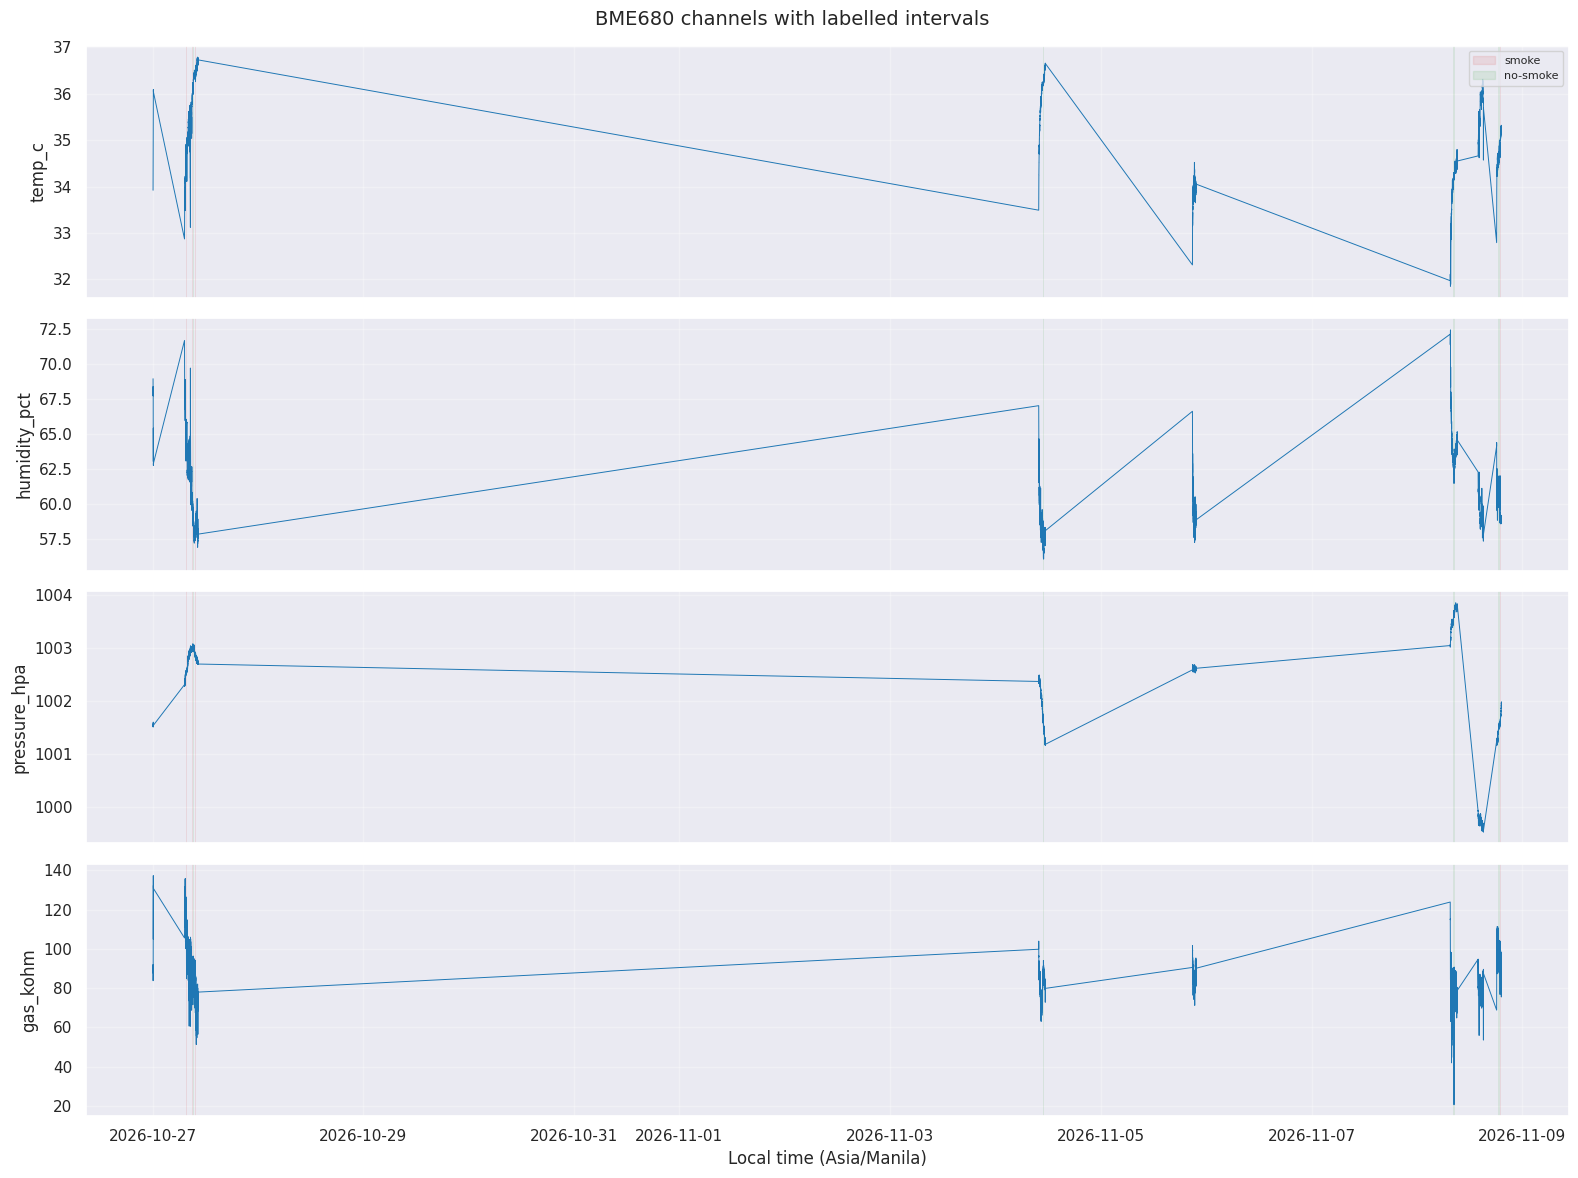

In [ ]:
PLOT_CHANNELS = ['temp_c', 'humidity_pct', 'pressure_hpa', 'gas_kohm']

local_time = pd.to_datetime(
    SENSOR_DF['timestamp_real'], unit='s', utc=True
).dt.tz_convert(SESSION_TZ)

interval_spans = [
    (
        pd.to_datetime(float(row.start), unit='s', utc=True).tz_convert(SESSION_TZ),
        pd.to_datetime(float(row.stop), unit='s', utc=True).tz_convert(SESSION_TZ),
        CLASSES[int(row.label)],
    )
    for row in INTERVAL_TABLE.itertuples(index=False)
]

fig, axes = plt.subplots(4, 1, figsize=(16, 12), sharex=True)
for ax, channel in zip(axes, PLOT_CHANNELS):
    ax.plot(local_time, SENSOR_DF[channel], linewidth=0.7, color='tab:blue')
    for start, stop, label in interval_spans:
        color = 'tab:red' if label == 'smoke' else 'tab:green'
        ax.axvspan(start, stop, color=color, alpha=0.10, linewidth=0)
    ax.set_ylabel(channel)
    ax.grid(True, alpha=0.3)

axes[0].legend(
    handles=[
        plt.Rectangle((0, 0), 1, 1, color='tab:red', alpha=0.10),
        plt.Rectangle((0, 0), 1, 1, color='tab:green', alpha=0.10),
    ],
    labels=['smoke', 'no-smoke'], loc='upper right', fontsize=8,
)
axes[-1].set_xlabel(f'Local time ({SESSION_TZ})')
fig.suptitle('BME680 channels with labelled intervals', fontsize=14)
fig.tight_layout()
plt.show()


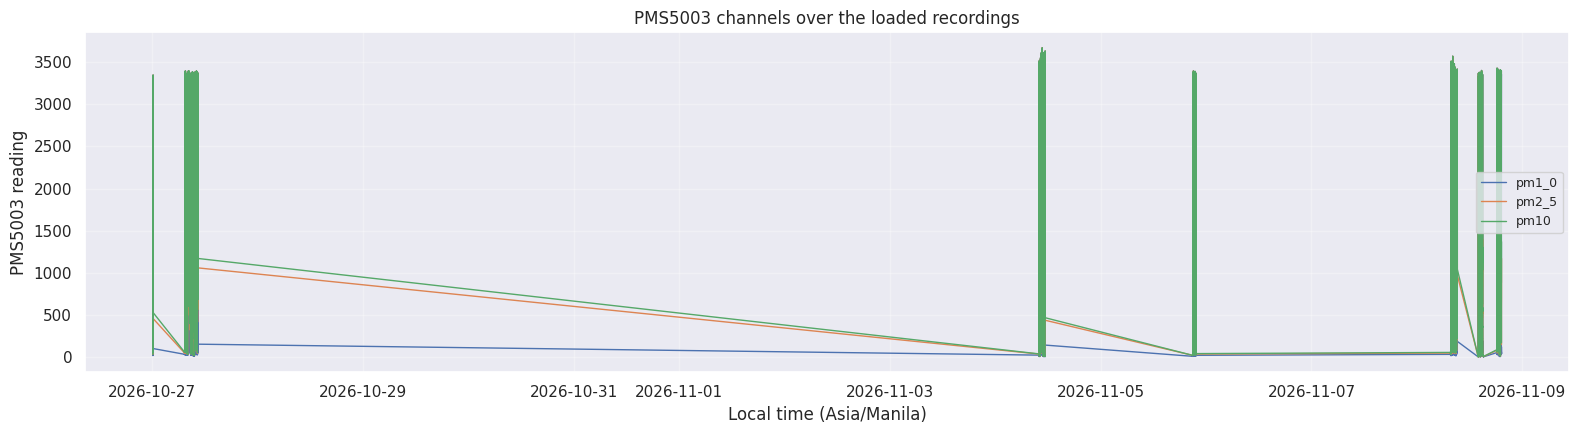

PMS5003 constancy check:
  pm1_0    min=     0.000 max=  3673.000 std=972.1947 nunique=  283
  pm2_5    min=     1.000 max=  3673.000 std=956.3783 nunique= 1549
  pm10     min=     1.000 max=  3673.000 std=975.2714 nunique= 1894


In [ ]:
pm_channels = [channel for channel in ['pm1_0', 'pm2_5', 'pm10']
               if channel in SENSOR_DF.columns]

fig, ax = plt.subplots(figsize=(16, 4.5))
for channel in pm_channels:
    ax.plot(local_time, SENSOR_DF[channel], linewidth=1.0, label=channel)
ax.set_xlabel(f'Local time ({SESSION_TZ})')
ax.set_ylabel('PMS5003 reading')
ax.set_title('PMS5003 channels over the loaded recordings')
ax.legend(loc='center right', fontsize=9)
ax.grid(True, alpha=0.3)
fig.tight_layout()
plt.show()

print('PMS5003 constancy check:')
for channel in pm_channels:
    series = SENSOR_DF[channel]
    print(f'  {channel:8s} min={series.min():10.3f} max={series.max():10.3f} '
          f'std={series.std():8.4f} nunique={series.nunique():5d}')
if all(SENSOR_DF[channel].nunique() == 1 for channel in pm_channels):
    print('\nAll PM channels are constant across the loaded recordings: the '
          'indoor air quality did not vary. Their statistics are therefore '
          'zero-variance on the training split and are dropped automatically. '
          'They will rejoin the model when a recording shows variation.')


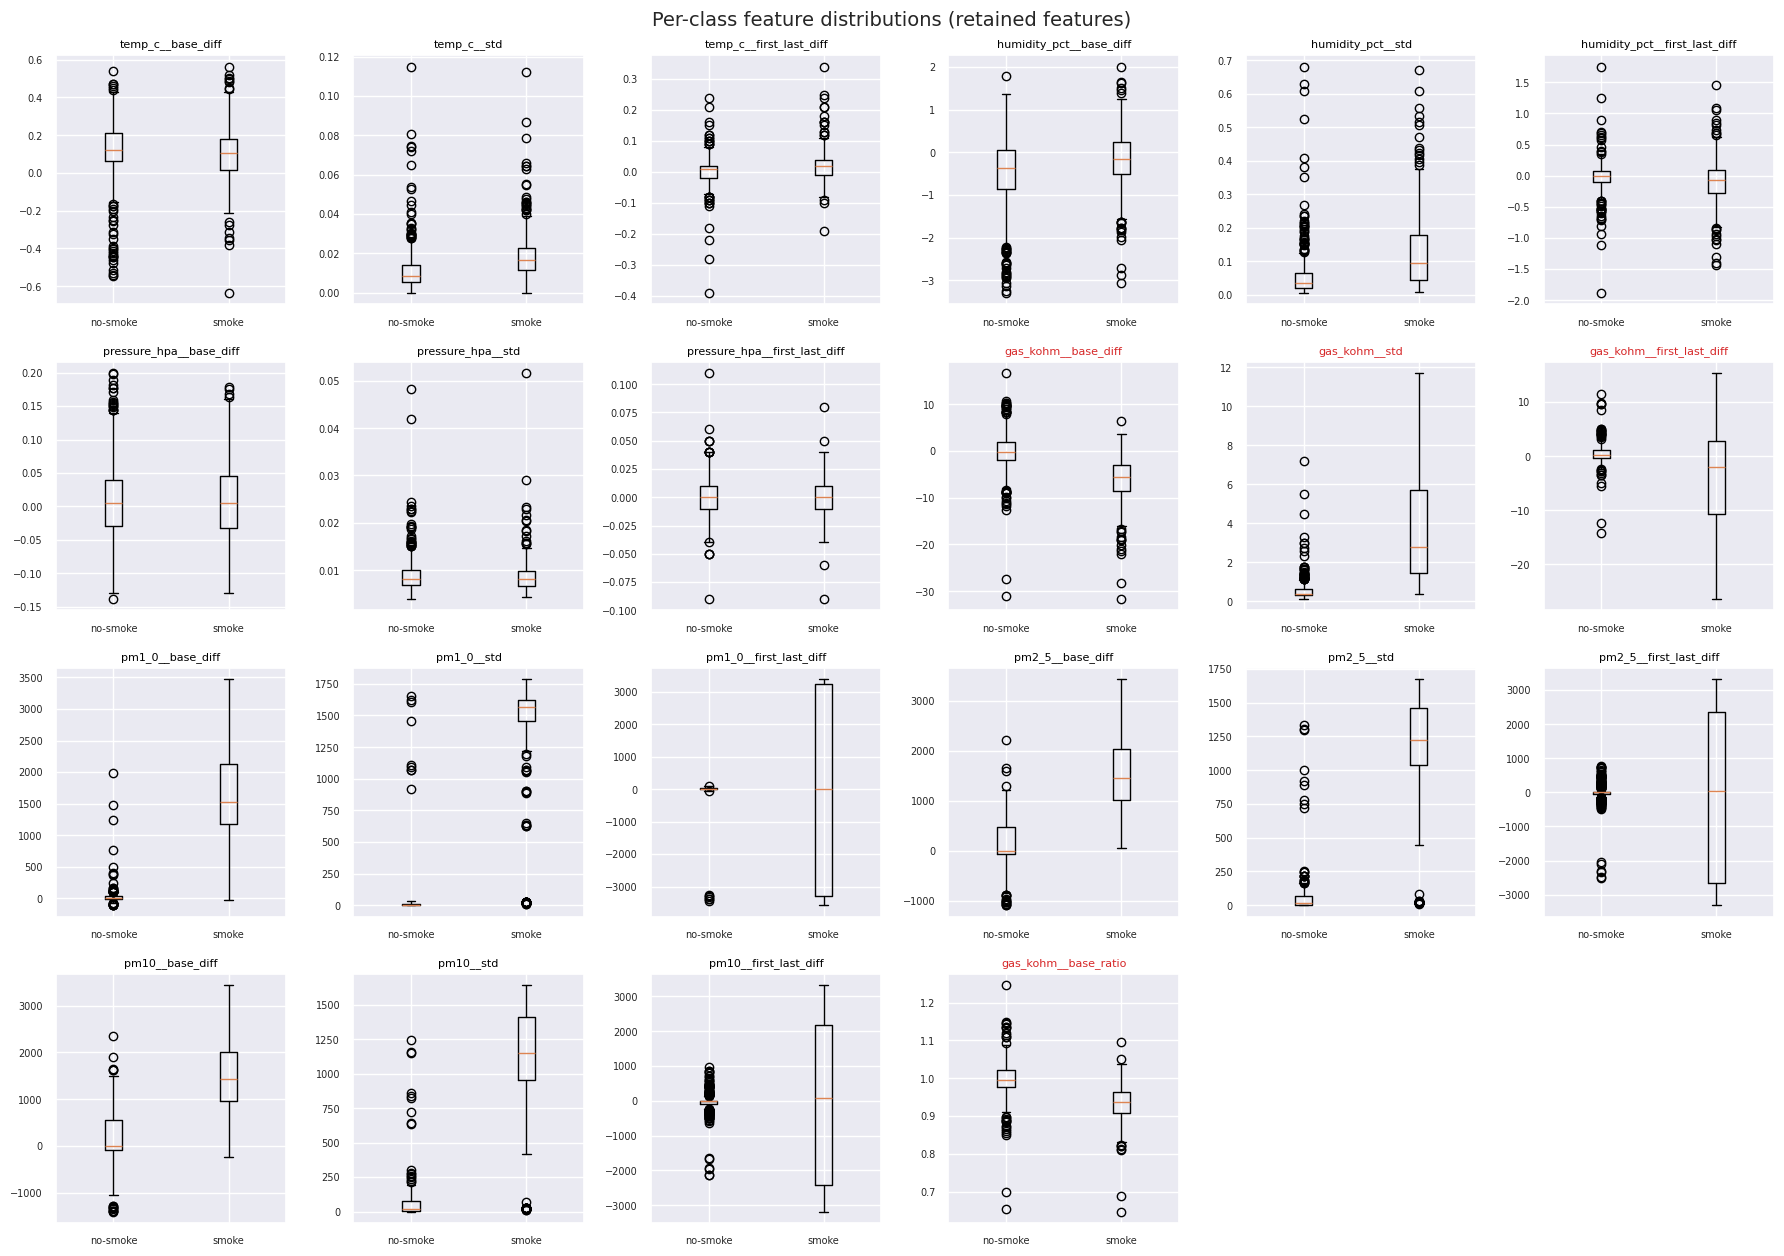

In [ ]:
n_features = len(FEATURE_NAMES)
n_cols = 6
n_rows = int(np.ceil(n_features / n_cols))
fig, axes = plt.subplots(n_rows, n_cols, figsize=(18, 3.2 * n_rows))
axes = np.atleast_1d(axes).ravel()

for ax, name in zip(axes, FEATURE_NAMES):
    index = FEATURE_NAMES.index(name)
    values = X[:, index]
    ax.boxplot([values[y == 0], values[y == 1]])
    ax.set_xticklabels([CLASSES[0], CLASSES[1]])
    title_color = 'tab:red' if name.startswith('gas_kohm') else 'black'
    ax.set_title(name, fontsize=8, color=title_color)
    ax.tick_params(labelsize=7)

for ax in axes[n_features:]:
    ax.axis('off')

fig.suptitle('Per-class feature distributions (retained features)', fontsize=14)
fig.tight_layout()
plt.show()


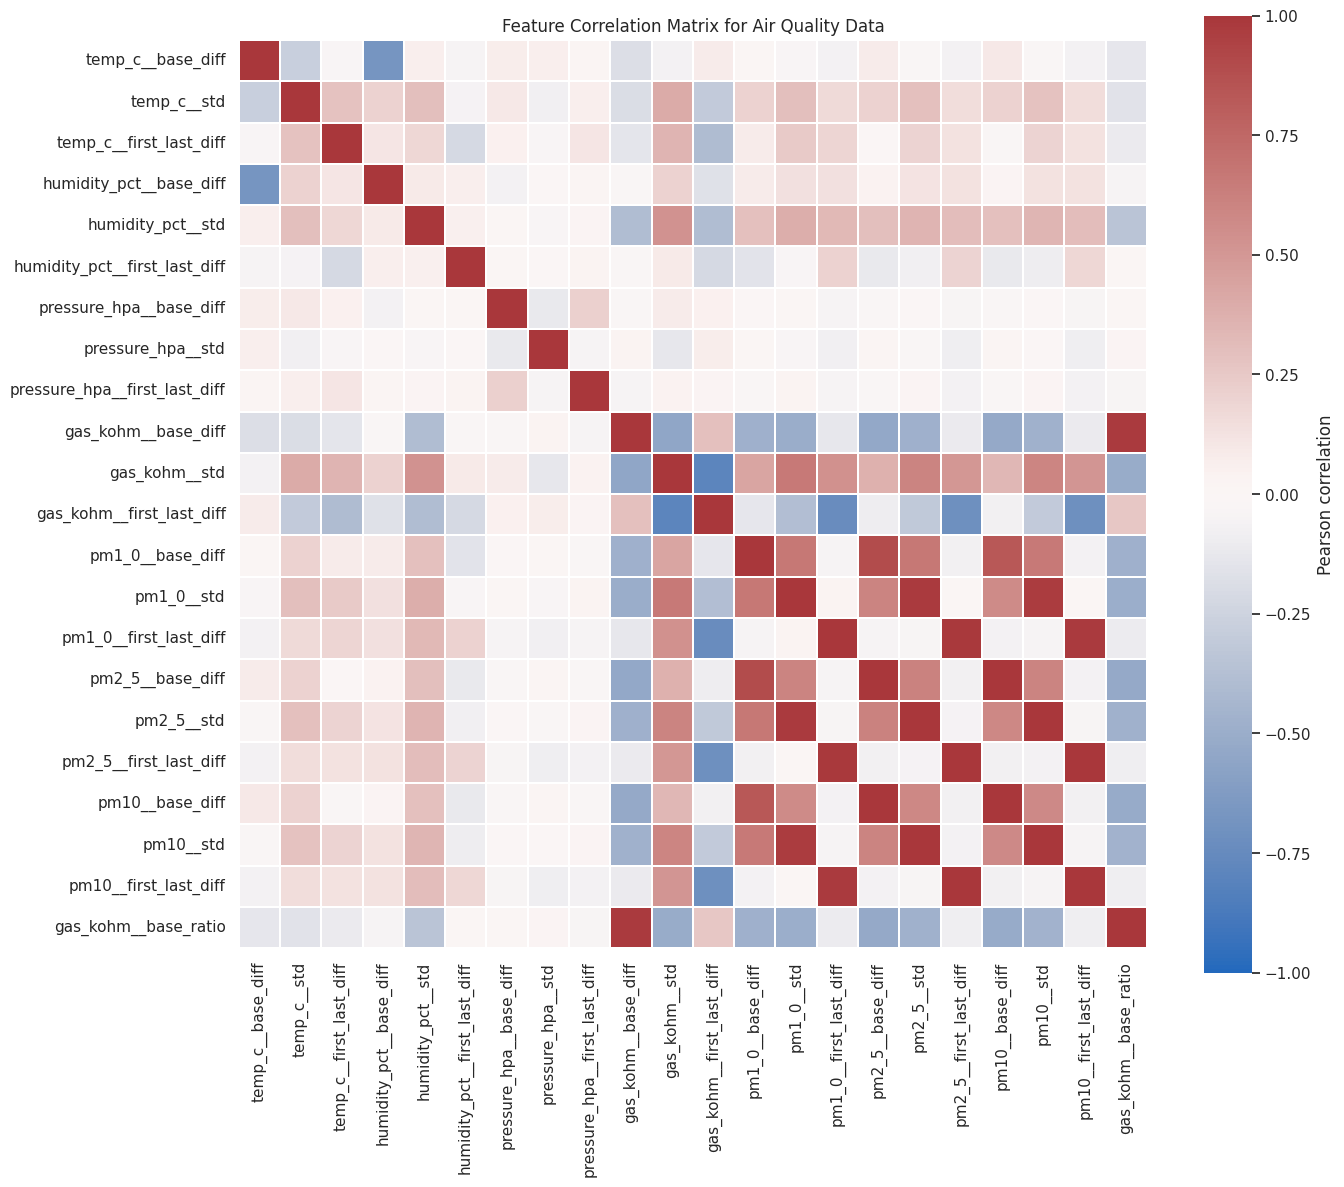

In [ ]:
correlation = pd.DataFrame(X, columns=FEATURE_NAMES).corr()

fig, ax = plt.subplots(figsize=(14, 12))
sns.heatmap(
    correlation, cmap='vlag', center=0.0, vmin=-1.0, vmax=1.0,
    square=True, linewidths=0.3, cbar_kws={'label': 'Pearson correlation'},
    ax=ax,
)
ax.set_title('Feature Correlation Matrix for Air Quality Data')
fig.tight_layout()
plt.show()


## 4. Model

### Soft-margin SVM

Sensor readings are noisy: a hard-margin separator would be forced to fit every wobbly interval, which generalises poorly. The soft-margin formulation allows violations `xi_i >= 0` and trades them against the margin width:

**minimize  0.5 * ||w||^2 + C * sum(xi_i)   subject to  y_i (w . phi(x_i) + b) >= 1 - xi_i**

The regularisation term `C` is selected by grid search. A small `C` tolerates more misclassifications; a large `C` fits the training intervals more tightly.

### RBF kernel

The separator is nonlinear in the raw features, so the SVM uses the RBF kernel `K(x_i, x_j) = exp(-gamma * ||x_i - x_j||^2)`. `gamma` is selected by the same grid search. Features are standardised inside the pipeline, which is required for a meaningful RBF distance.

### Session-robust VOC features

An SVM trained on absolute sensor levels learns the ambient baseline of the training recordings. That baseline drifts through a session, so the OOF-tuned probability threshold does not transfer to a later session even when the ranking is perfect. The feature vector therefore contains **no absolute levels**: every channel is represented by its within-window dynamics (`std`, `first_last_diff`) and by its mean relative to the preceding baseline median (`base_diff`), with an explicit gas baseline ratio. This is the VOC-index idea generalised to all channels. The features are causal and can be computed at deployment from a rolling sensor buffer.

### Platt scaling

An SVM decision function returns a signed distance, not a probability. Platt scaling fits a sigmoid over it:

**P(smoke | x) = 1 / (1 + exp(A * d(x) + B))**

where `d(x)` is the SVM decision value. sklearn fits `A` and `B` by maximum likelihood with an internal stratified 5-fold cross-validation on the training split. The fitted `probA_` / `probB_` values are recorded in the model metadata.

There is no validation split in this notebook. The standalone threshold is selected on **grouped out-of-fold training predictions** (whole recordings stay in one fold), and calibration is checked on the held-out test file. The fusion layer re-tunes its own threshold on its validation data.

### Compatibility with late fusion

The late-fusion layer consumes calibrated probabilities: `p_final = w1 * p_CSI + w2 * p_smoke`, with weights and threshold tuned on validation data. This notebook therefore exposes:

- `pipeline.predict_proba(X)[:, 1]` → calibrated `P(smoke)` for any feature matrix;
- a reference `extract_features_for_inference` helper that turns a sensor buffer (the frozen window plus the preceding baseline window) into the exact feature order the pipeline expects;
- `A`, `B`, `WINDOW_SECONDS`, `BASELINE_SECONDS`, and the standalone threshold in `smoke_svm.meta.json`.

### Mapping to the thesis feature vector

| Thesis feature | This notebook |
|---|---|
| Temperature | `temp_c` dynamics and baseline-relative mean |
| Humidity | `humidity_pct` dynamics and baseline-relative mean |
| VOC Index | `gas_kohm` dynamics, baseline-relative mean, and baseline ratio (gas resistance drops under exposure) |
| PM1.0 / PM2.5 / PM10 | `pm1_0` / `pm2_5` / `pm10` dynamics and baseline-relative means — retained automatically when they vary; dropped when constant |
| AQI | not derivable from the raw stream without a defined formula, so it is omitted |
| Window length | `WINDOW_SECONDS`, derived from the mean observed training-interval duration (the fixed thesis figure is superseded by the data-derived value) |


In [ ]:
def build_pipeline():
    """StandardScaler -> soft-margin RBF SVC with Platt scaling."""
    return Pipeline([
        ('scaler', StandardScaler()),
        ('svc', SVC(
            kernel=SVM_KERNEL,
            class_weight=SVM_CLASS_WEIGHT,
            probability=SVM_PROBABILITY,
            random_state=RANDOM_SEED,
        )),
    ])


PARAMETER_GRID = {
    'svc__C': list(SVM_C_GRID),
    'svc__gamma': list(SVM_GAMMA_GRID),
}

n_candidates = int(np.prod([len(values) for values in PARAMETER_GRID.values()]))
c_grid_text = ', '.join(f'{value:.4g}' for value in SVM_C_GRID)
print(f'Pipeline: {[step[0] for step in build_pipeline().steps]}')
print(f'Grid: {n_candidates} candidate(s) | C=[{c_grid_text}] | '
      f'gamma={SVM_GAMMA_GRID}')
print(f'CV: StratifiedGroupKFold (up to {CV_FOLDS} folds, grouped by '
      f'source_file); scoring={GRID_SCORING}')
print(f'Platt scaling: probability={SVM_PROBABILITY} '
      '(internal stratified 5-fold CV on the training split)')


Pipeline: ['scaler', 'svc']
Grid: 36 candidate(s) | C=[0.01, 0.04217, 0.1778, 0.7499, 3.162, 13.34, 56.23, 237.1, 1000] | gamma=['scale', 'auto', 0.1, 1.0]
CV: StratifiedGroupKFold (up to 5 folds, grouped by source_file); scoring=f1
Platt scaling: probability=True (internal stratified 5-fold CV on the training split)


## 5. Training

The model is trained on every non-test observation file in the frozen file split. The held-out test file is never used for fitting, hyperparameter selection, or threshold tuning.

Training settings:

- Soft-margin RBF SVC, `class_weight='balanced'`, Platt scaling enabled.
- Grid search over `C` and `gamma` with **grouped 5-fold cross-validation** on the training split, scored by F1. Intervals from one recording stay in one fold, so the CV score measures cross-recording generalisation.
- Features standardised inside the pipeline, so the scaler is fitted on training folds only.

Each run has a provenance fingerprint over the frozen split, the interval identities and labels, the feature schema, the model configuration, and the training tensors. If the fingerprint matches the saved checkpoint, training is skipped. If anything changed, the previous checkpoint is archived under `history/` and the model is refitted. `FORCE_RETRAIN=True` forces a refit regardless.


In [ ]:
def _hash_array(array):
    return hashlib.sha256(np.ascontiguousarray(array).tobytes()).hexdigest()


def _hash_strings(strings):
    return hashlib.sha256(
        '\n'.join(sorted(str(value) for value in strings)).encode('utf-8')
    ).hexdigest()


def _preprocessing_fingerprint():
    return hashlib.sha256(json.dumps({
        'sensor_channels': list(SENSOR_CHANNELS),
        'window_stats': list(WINDOW_STATS),
        'baseline_stats': list(BASELINE_STATS),
        'baseline_channel': BASELINE_CHANNEL,
        'baseline_seconds': float(BASELINE_SECONDS),
        'min_baseline_samples': int(MIN_BASELINE_SAMPLES),
        'include_duration': bool(INCLUDE_DURATION),
        'min_samples_per_interval': int(MIN_SAMPLES_PER_INTERVAL),
        'zero_variance_eps': float(ZERO_VARIANCE_EPS),
        'window_seconds': float(WINDOW_SECONDS),
        'window_source': WINDOW_SOURCE,
        'classes': list(CLASSES),
        'pairing': 'same_file',
        'scaler': 'standardscaler',
        'feature_names': list(FEATURE_NAMES),
        'dropped_columns': sorted(DROPPED_COLUMNS),
    }, sort_keys=True).encode('utf-8')).hexdigest()


def _training_config_payload():
    return {
        'architecture': 'soft_margin_rbf_svc_platt',
        'kernel': SVM_KERNEL,
        'class_weight': SVM_CLASS_WEIGHT,
        'probability': bool(SVM_PROBABILITY),
        'c_grid': [float(value) for value in SVM_C_GRID],
        'gamma_grid': [str(value) for value in SVM_GAMMA_GRID],
        'cv_strategy': 'StratifiedGroupKFold',
        'cv_folds': int(CV_FOLDS),
        'scoring': GRID_SCORING,
        'random_seed': int(RANDOM_SEED),
        'window_seconds': float(WINDOW_SECONDS),
        'baseline_seconds': float(BASELINE_SECONDS),
        'classes': list(CLASSES),
        'feature_names': list(FEATURE_NAMES),
    }


def _training_fingerprint(tag, data, split_hash):
    payload = {
        'tag': tag,
        'frozen_split_sha256': split_hash,
        'split_kind': 'file_holdout',
        'train_intervals_sha256': _hash_strings(data['train_interval_keys']),
        'test_intervals_sha256': _hash_strings(data['test_interval_keys']),
        'train_labels_sha256': _hash_array(data['y_train']),
        'test_labels_sha256': _hash_array(data['y_test']),
        'preprocessing_sha256': _preprocessing_fingerprint(),
        'training_config': _training_config_payload(),
        'x_train_sha256': _hash_array(data['X_train']),
        'x_test_sha256': _hash_array(data['X_test']),
    }
    return hashlib.sha256(
        json.dumps(payload, sort_keys=True, separators=(',', ':')).encode('utf-8')
    ).hexdigest()


def _load_pipeline(path):
    return joblib.load(path)


def prepare_svm_data(file_indices):
    """Slice the feature matrix into train/test arrays and build grouped CV."""
    train_idx = file_indices['train']
    test_idx = file_indices['test']

    train_groups = np.asarray(SOURCE_FILES[train_idx], dtype=object)
    for group in np.unique(train_groups):
        group_labels = y[train_idx][train_groups == group]
        if len(np.unique(group_labels)) < len(CLASSES):
            raise FileSplitError(
                f'Training file {group} does not contain all classes; grouped '
                'CV cannot stratify it.'
            )
    cv = build_group_cv(train_groups)

    data = {
        'indices': file_indices,
        'train_idx': train_idx,
        'test_idx': test_idx,
        'X_train': X[train_idx],
        'y_train': y[train_idx],
        'X_test': X[test_idx],
        'y_test': y[test_idx],
        'train_groups': train_groups,
        'cv': cv,
        'train_interval_keys': INTERVAL_KEYS[train_idx],
        'test_interval_keys': INTERVAL_KEYS[test_idx],
    }
    print(f'[svm data] train={len(train_idx)}, test={len(test_idx)}; '
          f'features={X.shape[1]}; groups={len(np.unique(train_groups))}; '
          f'cv={type(cv).__name__}(n_splits={cv.get_n_splits()})')
    for name, idx in (('train', train_idx), ('test', test_idx)):
        counts = np.bincount(y[idx], minlength=len(CLASSES))
        print(f'  {name:>5}: ' + ', '.join(
            f'{class_name}={int(count)}'
            for class_name, count in zip(CLASSES, counts)
        ))
    return data


def load_or_train_model(tag, pipeline_path, meta_path, data, split_hash,
                        split_meta):
    """Load a matching checkpoint, or fit and save a new one."""
    os.makedirs(os.path.dirname(pipeline_path), exist_ok=True)
    os.makedirs(MODEL_HISTORY_DIR, exist_ok=True)
    os.makedirs(TRAINING_RUN_DIR, exist_ok=True)

    training_config = _training_config_payload()
    training_fingerprint = _training_fingerprint(tag, data, split_hash)

    pipeline_on_disk = os.path.exists(pipeline_path)
    meta_on_disk = os.path.exists(meta_path)
    model_meta = None
    if meta_on_disk:
        try:
            with open(meta_path, 'r', encoding='utf-8') as f:
                model_meta = json.load(f)
        except (OSError, json.JSONDecodeError) as exc:
            print(f'[training:{tag}] WARNING: unreadable model metadata '
                  f'({exc}); will retrain.')
            model_meta = None

    classes_match = (
        model_meta is not None and model_meta.get('classes') == list(CLASSES)
    )
    features_match = (
        model_meta is not None
        and model_meta.get('feature_config', {}).get('feature_names')
        == list(FEATURE_NAMES)
    )
    fingerprint_matches = bool(
        pipeline_on_disk
        and model_meta is not None
        and model_meta.get('training_fingerprint') == training_fingerprint
        and classes_match
        and features_match
    )

    if fingerprint_matches and not FORCE_RETRAIN:
        try:
            pipeline = _load_pipeline(pipeline_path)
            print(f'[training:{tag}] fingerprint matches; loaded checkpoint '
                  'and skipped fit.')
            print(f'[training:{tag}] fingerprint: '
                  f'{training_fingerprint[:16]}...')
            return pipeline, None, model_meta
        except Exception as exc:
            print(f'[training:{tag}] checkpoint load failed ({exc}); '
                  'retraining fresh.')

    if pipeline_on_disk or meta_on_disk:
        stamp = datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%SZ')
        if pipeline_on_disk:
            shutil.copy2(
                pipeline_path,
                os.path.join(MODEL_HISTORY_DIR, f'{tag}.{stamp}.joblib'),
            )
        if meta_on_disk:
            shutil.copy2(
                meta_path,
                os.path.join(MODEL_HISTORY_DIR, f'{tag}.{stamp}.meta.json'),
            )
        print(f'[training:{tag}] archived the previous checkpoint under '
              f'{MODEL_HISTORY_DIR}')

    run_id = datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%S%fZ')
    run_log_path = os.path.join(TRAINING_RUN_DIR, f'{tag}.{run_id}.json')
    run_log = {
        'run_id': run_id,
        'tag': tag,
        'status': 'started',
        'started_at_utc': utc_now_iso(),
        'training_fingerprint': training_fingerprint,
        'training_config': training_config,
        'split_meta': split_meta,
        'classes': list(CLASSES),
        'frozen_split_sha256': split_hash,
        'window_seconds': float(WINDOW_SECONDS),
        'baseline_seconds': float(BASELINE_SECONDS),
        'feature_names': list(FEATURE_NAMES),
        'n_train': int(len(data['train_idx'])),
        'n_test': int(len(data['test_idx'])),
        'force_retrain': bool(FORCE_RETRAIN),
        'early_stopping': False,
        'selection_metric': 'group_cv_f1',
    }
    _atomic_write_json(run_log_path, run_log)

    print(f'[training:{tag}] fitting soft-margin RBF SVM with '
          f'{n_candidates} grid candidate(s) x '
          f'{data["cv"].get_n_splits()}-fold grouped CV...')
    grid = GridSearchCV(
        build_pipeline(),
        PARAMETER_GRID,
        scoring=GRID_SCORING,
        cv=data['cv'],
        refit=True,
        n_jobs=-1,
        verbose=0,
    )
    grid.fit(
        data['X_train'], data['y_train'], groups=data['train_groups']
    )
    best_pipeline = grid.best_estimator_

    svc = best_pipeline.named_steps['svc']
    platt_a = (
        float(np.ravel(getattr(svc, 'probA_', [0.0]))[0])
        if SVM_PROBABILITY else None
    )
    platt_b = (
        float(np.ravel(getattr(svc, 'probB_', [0.0]))[0])
        if SVM_PROBABILITY else None
    )

    joblib.dump(best_pipeline, pipeline_path)
    best_C = float(grid.best_params_['svc__C'])
    best_gamma = grid.best_params_['svc__gamma']
    if not isinstance(best_gamma, str):
        best_gamma = float(best_gamma)
    best_cv_f1 = float(grid.best_score_)
    cv_mean = float(grid.cv_results_['mean_test_score'][grid.best_index_])
    cv_std = float(grid.cv_results_['std_test_score'][grid.best_index_])
    n_groups = int(len(np.unique(data['train_groups'])))

    meta = {
        'schema_version': 2,
        'tag': tag,
        'classes': list(CLASSES),
        'model_path': pipeline_path,
        'training_fingerprint': training_fingerprint,
        'frozen_split_sha256': split_hash,
        'split_meta': split_meta,
        'preprocessing': {
            'window_seconds': float(WINDOW_SECONDS),
            'window_source': WINDOW_SOURCE,
            'min_samples_per_interval': int(MIN_SAMPLES_PER_INTERVAL),
            'baseline_channel': BASELINE_CHANNEL,
            'baseline_seconds': float(BASELINE_SECONDS),
            'min_baseline_samples': int(MIN_BASELINE_SAMPLES),
        },
        'feature_config': {
            'channels': list(SENSOR_CHANNELS),
            'window_stats': list(WINDOW_STATS),
            'baseline_stats': list(BASELINE_STATS),
            'include_duration': bool(INCLUDE_DURATION),
            'dropped_columns': DROPPED_COLUMNS,
            'feature_names': list(FEATURE_NAMES),
            'scaler': 'standardscaler',
        },
        'svm_params': {
            'kernel': SVM_KERNEL,
            'C': best_C,
            'gamma': best_gamma,
            'class_weight': SVM_CLASS_WEIGHT,
            'probability': bool(SVM_PROBABILITY),
            'random_state': int(RANDOM_SEED),
        },
        'grid': {
            'scoring': GRID_SCORING,
            'cv_strategy': 'StratifiedGroupKFold',
            'cv_folds': int(data['cv'].get_n_splits()),
            'n_groups': n_groups,
            'n_candidates': int(n_candidates),
            'best_params': {'C': best_C, 'gamma': best_gamma},
            'best_cv_f1': best_cv_f1,
            'cv_mean_f1': cv_mean,
            'cv_std_f1': cv_std,
        },
        'platt': {
            'A': platt_a,
            'B': platt_b,
            'method': 'sklearn_internal_stratified_5fold_cv',
            'note': (
                'A and B are fitted inside the training split. There is no '
                'validation split; the standalone threshold is tuned on '
                'grouped out-of-fold training predictions.'
            ),
        },
        'threshold': None,
        'dataset': {
            'n_train': int(len(data['train_idx'])),
            'n_test': int(len(data['test_idx'])),
            'n_features': int(X.shape[1]),
            'train_intervals_sha256': _hash_strings(data['train_interval_keys']),
            'test_intervals_sha256': _hash_strings(data['test_interval_keys']),
            'train_labels_sha256': _hash_array(data['y_train']),
            'test_labels_sha256': _hash_array(data['y_test']),
            'x_train_sha256': _hash_array(data['X_train']),
            'x_test_sha256': _hash_array(data['X_test']),
        },
        'versions': {
            'sklearn': sklearn.__version__,
            'joblib': joblib.__version__,
            'numpy': np.__version__,
            'pandas': pd.__version__,
        },
        'trained_at_utc': utc_now_iso(),
        'run_id': run_id,
        'selection_metric': 'group_cv_f1',
        'force_retrain': bool(FORCE_RETRAIN),
    }
    _atomic_write_json(meta_path, meta)

    cv_results = grid.cv_results_
    order = np.argsort(cv_results['rank_test_score'])
    top_candidates = []
    for index in order[:10]:
        params = cv_results['params'][index]
        gamma = params['svc__gamma']
        top_candidates.append({
            'rank': int(cv_results['rank_test_score'][index]),
            'C': float(params['svc__C']),
            'gamma': gamma if isinstance(gamma, str) else float(gamma),
            'mean_test_f1': float(cv_results['mean_test_score'][index]),
            'std_test_f1': float(cv_results['std_test_score'][index]),
        })
    _atomic_write_json(GRID_RESULTS_PATH, {
        'fingerprint': training_fingerprint,
        'scoring': GRID_SCORING,
        'cv_strategy': 'StratifiedGroupKFold',
        'cv_folds': int(data['cv'].get_n_splits()),
        'n_groups': n_groups,
        'n_candidates': int(n_candidates),
        'best_params': {'C': best_C, 'gamma': best_gamma},
        'best_cv_f1': best_cv_f1,
        'top_candidates': top_candidates,
    })

    print(f'[training:{tag}] best params: C={best_C:.6g}, gamma={best_gamma}')
    print(f'[training:{tag}] best grouped CV F1: {best_cv_f1:.4f} '
          f'(mean {cv_mean:.4f} +/- {cv_std:.4f})')
    print(f'[training:{tag}] saved pipeline to {pipeline_path}')
    print(f'[training:{tag}] saved provenance to {meta_path}')

    completed = dict(run_log)
    completed.update({
        'status': 'completed',
        'finished_at_utc': utc_now_iso(),
        'best_params': {'C': best_C, 'gamma': best_gamma},
        'best_cv_f1': best_cv_f1,
        'platt': {'A': platt_a, 'B': platt_b},
        'pipeline_path': pipeline_path,
        'meta_path': meta_path,
    })
    _atomic_write_json(run_log_path, completed)
    return best_pipeline, grid, meta


In [ ]:
if X.size == 0:
    raise RuntimeError('No feature windows found; run Section 2 first.')

SVM_DATA = prepare_svm_data(FILE_INDICES)

SVM_PIPELINE, SVM_GRID, SVM_META = load_or_train_model(
    tag='smoke_svm_rbf_file',
    pipeline_path=PIPELINE_PATH,
    meta_path=META_PATH,
    data=SVM_DATA,
    split_hash=file_split_sha256(FILE_SPLIT),
    split_meta={
        'kind': 'file_holdout',
        'test_files': FILE_SPLIT['test_files'],
        'train_files': FILE_SPLIT['train_files'],
        'revision': FILE_SPLIT['revision'],
        'initial_split_sha256': FILE_SPLIT['initial_split_sha256'],
        'window_seconds': FILE_SPLIT['window_seconds'],
    },
)


[svm data] train=598, test=108; features=22; groups=5; cv=StratifiedGroupKFold(n_splits=5)
  train: no-smoke=363, smoke=235
   test: no-smoke=73, smoke=35
[training:smoke_svm_rbf_file] fingerprint matches; loaded checkpoint and skipped fit.
[training:smoke_svm_rbf_file] fingerprint: ef4cf62ea1314126...


## 6. Evaluation results

This section reports six views:

1. **Grid results** — the best SVM configurations from grouped cross-validation on the training recordings.
2. **Threshold selection** — the F1-max sweep over grouped out-of-fold training predictions.
3. **Test metrics** — accuracy, balanced accuracy, precision, recall, F1, ROC-AUC, AP, and Brier score on the held-out test recording.
4. **Confusion matrix** — the thresholded smoke / no-smoke decision.
5. **ROC and precision-recall curves** — unthresholded ranking quality.
6. **Calibration** — reliability diagram and probability histogram, verifying that `P(smoke)` is usable by the late-fusion layer.

Metric definitions:

- The test set is the whole `TEST_DATA.csv` recording (corrected span 18:12–19:15 Asia/Manila on 2026-11-08). All 108 labelled intervals produce feature windows after the timestamp repair.
- There is no validation split. The threshold is tuned on grouped out-of-fold training predictions, so the test file is never used for tuning.
- ROC-AUC and AP use the unthresholded `P(smoke)` on the test split.
- Brier score measures the mean squared error of the calibrated probabilities (lower is better).
- The standalone threshold stored in the metadata is an anchor; the fusion layer re-tunes its threshold on the fused score.


In [ ]:
# ---------------------------------------------------------------------------
# 1. Grid results from the training-only cross-validation.
# ---------------------------------------------------------------------------
if os.path.exists(GRID_RESULTS_PATH):
    with open(GRID_RESULTS_PATH, 'r', encoding='utf-8') as f:
        grid_payload = json.load(f)
    grid_table = pd.DataFrame(grid_payload['top_candidates']).set_index('rank')
else:
    grid_payload = None
    grid_table = None

if grid_table is not None:
    print(f"Grid search: {grid_payload['n_candidates']} candidate(s), "
          f"{grid_payload['cv_folds']}-fold CV on the training split, "
          f"scoring={grid_payload['scoring']}")
    print(f"Best params: C={grid_payload['best_params']['C']:.6g}, "
          f"gamma={grid_payload['best_params']['gamma']}")
    display(grid_table.round(4))
else:
    print('No saved grid results found; rerun Section 5 to fit the model.')


Grid search: 36 candidate(s), 5-fold CV on the training split, scoring=f1
Best params: C=0.749894, gamma=scale


,C,gamma,mean_test_f1,std_test_f1
rank,,,,
1,0.7499,scale,0.9613,0.0267
1,0.7499,auto,0.9613,0.0267
3,13.3352,0.1,0.9534,0.0194
4,3.1623,scale,0.9530,0.0463
4,3.1623,auto,0.9530,0.0463
6,0.1778,auto,0.9509,0.0244
6,0.1778,scale,0.9509,0.0244
8,3.1623,0.1,0.9503,0.0253
9,56.2341,0.1,0.9463,0.0203


In [ ]:
# ---------------------------------------------------------------------------
# 2-3. Threshold selection on grouped OOF training predictions and the
# held-out test metrics. There is no validation set.
# ---------------------------------------------------------------------------
def tune_threshold(y_true_binary, positive_prob):
    """Select the F1-maximising threshold on grouped OOF training predictions."""
    precision, recall, thresholds = precision_recall_curve(
        y_true_binary, positive_prob
    )
    if len(thresholds) == 0:
        raise RuntimeError('Could not tune a smoke threshold.')
    precision = precision[:-1]
    recall = recall[:-1]
    f1 = 2.0 * precision * recall / (precision + recall + 1e-12)
    if THRESHOLD_OBJECTIVE == 'precision':
        valid = np.flatnonzero(precision >= 0.80)
        index = int(valid[np.argmax(recall[valid])]) if len(valid) else int(np.argmax(f1))
    else:
        index = int(np.argmax(f1))
    return float(thresholds[index]), float(precision[index]), float(recall[index])


def evaluate_svm(name, pipeline, data):
    """Return OOF threshold, test metrics, curves, and calibration data."""
    oof_prob = cross_val_predict(
        clone(pipeline),
        data['X_train'],
        data['y_train'],
        cv=data['cv'],
        groups=data['train_groups'],
        method='predict_proba',
        n_jobs=-1,
    )[:, POSITIVE_CLASS_IDX]
    test_prob = pipeline.predict_proba(data['X_test'])[:, POSITIVE_CLASS_IDX]

    train_binary = (data['y_train'] == POSITIVE_CLASS_IDX).astype(int)
    test_binary = (data['y_test'] == POSITIVE_CLASS_IDX).astype(int)

    threshold, oof_precision, oof_recall = tune_threshold(
        train_binary, oof_prob
    )
    oof_pred = (oof_prob >= threshold).astype(int)
    test_pred = (test_prob >= threshold).astype(int)

    cm = confusion_matrix(test_binary, test_pred, labels=[0, 1])
    tn, fp, fn, tp = cm.ravel()

    roc_fpr, roc_tpr, _ = roc_curve(test_binary, test_prob)
    pr_precision, pr_recall, _ = precision_recall_curve(test_binary, test_prob)

    sweep_rows = []
    for candidate in np.linspace(0.05, 0.95, 37):
        prediction = (oof_prob >= candidate).astype(int)
        sweep_rows.append({
            'threshold': float(candidate),
            'f1': float(f1_score(train_binary, prediction, zero_division=0)),
            'precision': float(precision_score(train_binary, prediction, zero_division=0)),
            'recall': float(recall_score(train_binary, prediction, zero_division=0)),
        })
    sweep = pd.DataFrame(sweep_rows)

    metrics = {
        'name': name,
        'n_train': int(len(train_binary)),
        'n_test': int(len(test_binary)),
        'threshold': threshold,
        'train_oof_precision': oof_precision,
        'train_oof_recall': oof_recall,
        'train_oof_f1_at_threshold': float(f1_score(
            train_binary, oof_pred, zero_division=0
        )),
        'test_accuracy': float(accuracy_score(test_binary, test_pred)),
        'test_balanced_accuracy': float(balanced_accuracy_score(
            test_binary, test_pred
        )),
        'test_precision': float(precision_score(
            test_binary, test_pred, zero_division=0
        )),
        'test_recall': float(recall_score(
            test_binary, test_pred, zero_division=0
        )),
        'test_f1': float(f1_score(test_binary, test_pred, zero_division=0)),
        'test_ap': float(average_precision_score(test_binary, test_prob)),
        'test_roc_auc': float(roc_auc_score(test_binary, test_prob)),
        'test_brier': float(brier_score_loss(test_binary, test_prob)),
        'tn': int(tn), 'fp': int(fp), 'fn': int(fn), 'tp': int(tp),
    }

    print(f'[{name}] train={metrics["n_train"]}, test={metrics["n_test"]} '
          f'intervals; threshold={threshold:.4f} '
          f'(train OOF F1={metrics["train_oof_f1_at_threshold"]:.4f})')
    print(f'[{name}] accuracy={metrics["test_accuracy"]:.4f} | '
          f'balanced accuracy={metrics["test_balanced_accuracy"]:.4f}')
    print(f'[{name}] precision={metrics["test_precision"]:.4f} | '
          f'recall={metrics["test_recall"]:.4f} | F1={metrics["test_f1"]:.4f}')
    print(f'[{name}] ROC-AUC={metrics["test_roc_auc"]:.4f} | '
          f'AP={metrics["test_ap"]:.4f} | Brier={metrics["test_brier"]:.4f}')
    print(f'[{name}] TP={tp}, FP={fp}, FN={fn}, TN={tn}')

    return {
        'name': name,
        'metrics': metrics,
        'y_test': test_binary,
        'y_pred': test_pred,
        'test_prob': test_prob,
        'train_binary': train_binary,
        'train_oof_prob': oof_prob,
        'train_pred': oof_pred,
        'roc_fpr': roc_fpr,
        'roc_tpr': roc_tpr,
        'pr_precision': pr_precision,
        'pr_recall': pr_recall,
        'sweep': sweep,
        'confusion': cm,
    }


TEST_RESULTS = evaluate_svm(
    'file holdout (TEST_DATA.csv)', SVM_PIPELINE, SVM_DATA
)
SVM_METRICS = TEST_RESULTS['metrics']

# Persist the tuned threshold and evaluation summary alongside the pipeline so
# the fusion layer can read them without rerunning the notebook.
with open(META_PATH, 'r', encoding='utf-8') as f:
    meta_on_disk = json.load(f)
meta_on_disk['threshold'] = {
    'value': SVM_METRICS['threshold'],
    'objective': THRESHOLD_OBJECTIVE,
    'tuned_on': 'train_oof_group_cv',
    'train_oof_f1_at_threshold': SVM_METRICS['train_oof_f1_at_threshold'],
}
meta_on_disk['evaluation'] = SVM_METRICS
# Google Drive's FUSE mount does not always support os.replace(); write the
# JSON locally and copy it into Drive instead of an atomic rename.
local_tmp = '/content/smoke_svm.meta.json'
with open(local_tmp, 'w', encoding='utf-8') as f:
    json.dump(meta_on_disk, f, indent=2, sort_keys=True)
    f.write('\n')
shutil.copy2(local_tmp, META_PATH)
print(f'[meta] threshold and evaluation summary written to {META_PATH}')


[file holdout (TEST_DATA.csv)] train=598, test=108 intervals; threshold=0.4050 (train OOF F1=0.9688)
[file holdout (TEST_DATA.csv)] accuracy=0.9815 | balanced accuracy=0.9863
[file holdout (TEST_DATA.csv)] precision=0.9459 | recall=1.0000 | F1=0.9722
[file holdout (TEST_DATA.csv)] ROC-AUC=1.0000 | AP=1.0000 | Brier=0.0043
[file holdout (TEST_DATA.csv)] TP=35, FP=2, FN=0, TN=71
[meta] threshold and evaluation summary written to /content/drive/MyDrive/CSI_TRAINING/models/smoke_sensor_svm_v2/smoke_svm.meta.json


In [ ]:
# ---------------------------------------------------------------------------
# Residual-PM check: no-smoke intervals with high PM must not be flagged when
# the VOC/gas channel did not move like smoke.
# ---------------------------------------------------------------------------
test_keys = INTERVAL_KEYS[FILE_INDICES['test']]
test_intervals = (
    INTERVAL_TABLE.set_index('interval_key')
    .loc[test_keys]
    .reset_index()
)
if len(test_intervals) != len(FILE_INDICES['test']):
    raise RuntimeError(
        'Test interval lookup does not match the feature rows; check the '
        'interval_key mapping.'
    )

pm1_test = np.array([
    slice_interval(
        SENSOR_DF, row.start,
        min(row.stop, row.start + WINDOW_SECONDS),
    )['pm1_0'].mean()
    for row in test_intervals.itertuples()
])
gas_ratio = SVM_DATA['X_test'][:, FEATURE_NAMES.index('gas_kohm__base_ratio')]
y_test = SVM_DATA['y_test']
pred = TEST_RESULTS['y_pred']
prob = TEST_RESULTS['test_prob']

test_sources = sorted(set(SOURCE_FILES[FILE_INDICES['test']]))
test_sessions = sorted(set(SESSION_KEYS[FILE_INDICES['test']]))
print(f'Residual-PM check on the held-out test file(s) '
      f'{test_sources} (sessions: {", ".join(test_sessions)}):')
for cutoff in (100, 500, 1000):
    high = (y_test == 0) & (pm1_test >= cutoff)
    n = int(high.sum())
    if n:
        print(f'  no-smoke PM1>={cutoff}: n={n}, '
              f'flagged={int(pred[high].sum())}, '
              f'gas_ratio median={np.median(gas_ratio[high]):.3f}, '
              f'max P(smoke)={prob[high].max():.3f}')
    else:
        print(f'  no-smoke PM1>={cutoff}: n=0')

missed = (y_test == 1) & (pm1_test < 100)
print(f'  smoke PM1<100: n={int(missed.sum())}, '
      f'missed={int((pred[missed] == 0).sum())}')
print(f'  smoke PM1>=100: n={int(((y_test == 1) & (pm1_test >= 100)).sum())}, '
      f'detected={int(pred[(y_test == 1) & (pm1_test >= 100)].sum())}')


Residual-PM check on the held-out test file(s) ['TEST_DATA.csv'] (sessions: 2026-11-08 18:00, 2026-11-08 19:00):
  no-smoke PM1>=100: n=17, flagged=1, gas_ratio median=0.984, max P(smoke)=0.434
  no-smoke PM1>=500: n=0
  no-smoke PM1>=1000: n=0
  smoke PM1<100: n=0, missed=0
  smoke PM1>=100: n=35, detected=35


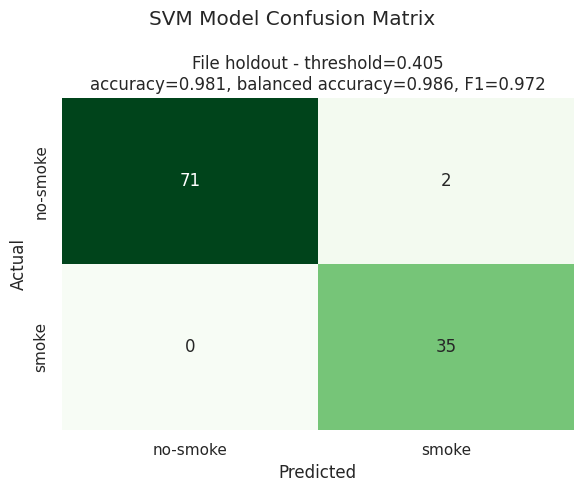

In [ ]:
# ---------------------------------------------------------------------------
# 4. Confusion matrix on the held-out test file.
# ---------------------------------------------------------------------------
fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(
    TEST_RESULTS['confusion'], annot=True, fmt='d', cmap='Greens',
    cbar=False, ax=ax, xticklabels=CLASSES, yticklabels=CLASSES,
)
metrics = TEST_RESULTS['metrics']
ax.set_xlabel('Predicted')
ax.set_ylabel('Actual')
ax.set_title(
    f"File holdout - threshold={metrics['threshold']:.3f}\n"
    f"accuracy={metrics['test_accuracy']:.3f}, "
    f"balanced accuracy={metrics['test_balanced_accuracy']:.3f}, "
    f"F1={metrics['test_f1']:.3f}"
)
fig.suptitle('SVM Model Confusion Matrix')
fig.tight_layout()
plt.show()


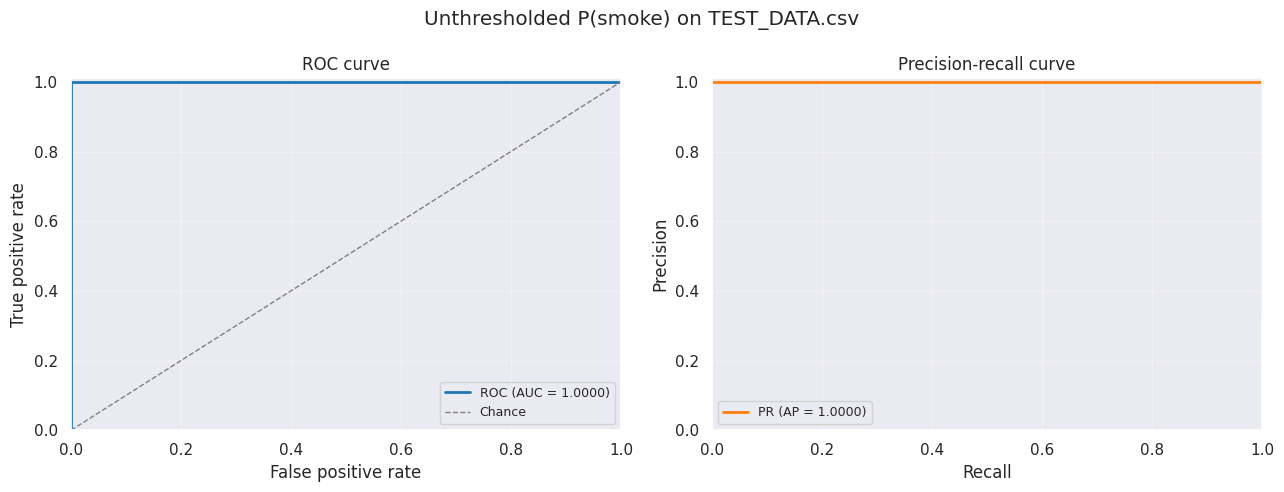

ROC-AUC: 1.0000 | AP: 1.0000 | threshold: 0.4050


In [ ]:
# ---------------------------------------------------------------------------
# 5. ROC and precision-recall curves on the held-out test file.
# ---------------------------------------------------------------------------
metrics = TEST_RESULTS['metrics']

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].plot(
    TEST_RESULTS['roc_fpr'], TEST_RESULTS['roc_tpr'],
    color='tab:blue', linewidth=2,
    label=f"ROC (AUC = {metrics['test_roc_auc']:.4f})",
)
axes[0].plot([0, 1], [0, 1], '--', color='grey', linewidth=1, label='Chance')
axes[0].set_xlim(0.0, 1.0)
axes[0].set_ylim(0.0, 1.01)
axes[0].set_xlabel('False positive rate')
axes[0].set_ylabel('True positive rate')
axes[0].set_title('ROC curve')
axes[0].legend(loc='lower right', fontsize=9)
axes[0].grid(True, alpha=0.3)

axes[1].plot(
    TEST_RESULTS['pr_recall'], TEST_RESULTS['pr_precision'],
    color='tab:orange', linewidth=2,
    label=f"PR (AP = {metrics['test_ap']:.4f})",
)
axes[1].set_xlim(0.0, 1.0)
axes[1].set_ylim(0.0, 1.01)
axes[1].set_xlabel('Recall')
axes[1].set_ylabel('Precision')
axes[1].set_title('Precision-recall curve')
axes[1].legend(loc='lower left', fontsize=9)
axes[1].grid(True, alpha=0.3)

fig.suptitle('Unthresholded P(smoke) on TEST_DATA.csv')
fig.tight_layout()
plt.show()

print(f"ROC-AUC: {metrics['test_roc_auc']:.4f} | AP: {metrics['test_ap']:.4f} | "
      f"threshold: {metrics['threshold']:.4f}")


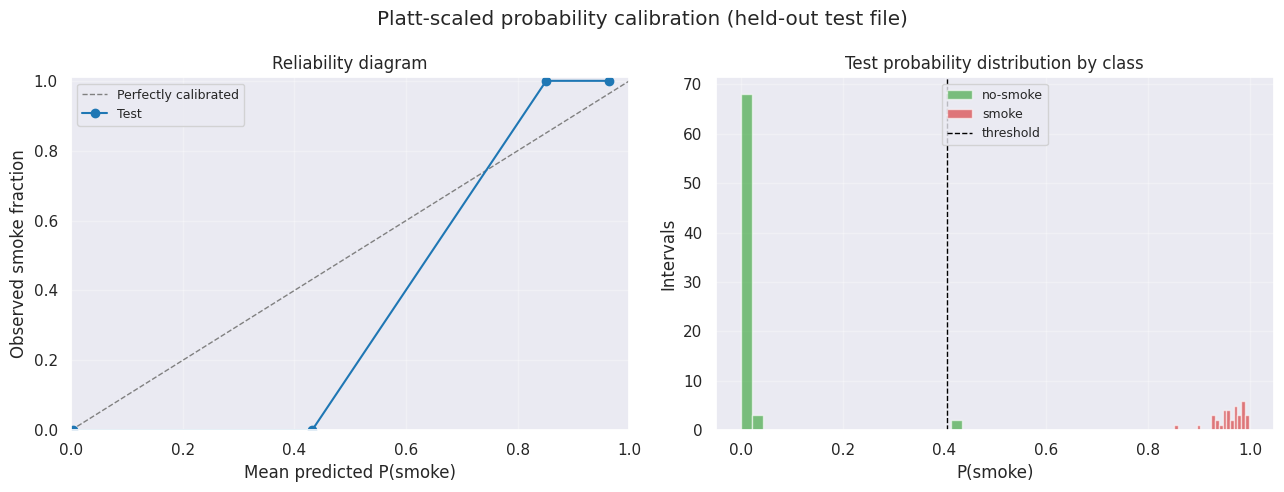

Brier score (test, lower is better): 0.0043
Platt parameters: A=-4.365311126979251, B=-1.0314958327157944


In [ ]:
# ---------------------------------------------------------------------------
# 6. Calibration on the held-out test file: reliability diagram, Brier score,
# and probability spread. There is no validation split.
# ---------------------------------------------------------------------------
test_fraction_positive, test_mean_prob = calibration_curve(
    TEST_RESULTS['y_test'], TEST_RESULTS['test_prob'],
    n_bins=10, strategy='uniform',
)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].plot([0, 1], [0, 1], '--', color='grey', linewidth=1,
             label='Perfectly calibrated')
axes[0].plot(test_mean_prob, test_fraction_positive, 'o-', color='tab:blue',
             label='Test')
axes[0].set_xlim(0.0, 1.0)
axes[0].set_ylim(0.0, 1.01)
axes[0].set_xlabel('Mean predicted P(smoke)')
axes[0].set_ylabel('Observed smoke fraction')
axes[0].set_title('Reliability diagram')
axes[0].legend(loc='upper left', fontsize=9)
axes[0].grid(True, alpha=0.3)

axes[1].hist(
    TEST_RESULTS['test_prob'][TEST_RESULTS['y_test'] == 0],
    bins=20, alpha=0.6, label='no-smoke', color='tab:green',
)
axes[1].hist(
    TEST_RESULTS['test_prob'][TEST_RESULTS['y_test'] == 1],
    bins=20, alpha=0.6, label='smoke', color='tab:red',
)
axes[1].axvline(TEST_RESULTS['metrics']['threshold'], color='black',
                linestyle='--', linewidth=1, label='threshold')
axes[1].set_xlabel('P(smoke)')
axes[1].set_ylabel('Intervals')
axes[1].set_title('Test probability distribution by class')
axes[1].legend(loc='upper center', fontsize=9)
axes[1].grid(True, alpha=0.3)

fig.suptitle('Platt-scaled probability calibration (held-out test file)')
fig.tight_layout()
plt.show()

print(f"Brier score (test, lower is better): "
      f"{TEST_RESULTS['metrics']['test_brier']:.4f}")
svc = SVM_PIPELINE.named_steps['svc']
print(f"Platt parameters: A={getattr(svc, 'probA_', [None])[0]}, "
      f"B={getattr(svc, 'probB_', [None])[0]}")


In [ ]:
# ---------------------------------------------------------------------------
# Fusion-interface contract and a reference runtime feature extractor.
# ---------------------------------------------------------------------------
def extract_features_for_inference(samples_df, window_seconds=None,
                                   baseline_seconds=None):
    """Reference extractor for the late-fusion layer.

    Parameters
    ----------
    samples_df : DataFrame with columns ``time`` plus ``SENSOR_CHANNELS``.
        Pass at least ``baseline_seconds + window_seconds`` of the most recent
        readings, ending at the decision time.
    window_seconds : float, optional. Defaults to the frozen WINDOW_SECONDS.
    baseline_seconds : float, optional. Defaults to BASELINE_SECONDS.

    Returns a ``(1, n_features)`` float matrix in the exact column order the
    saved pipeline expects. The window statistics use the last
    ``window_seconds``; the baseline uses the ``baseline_seconds`` immediately
    before that window (causal, past readings only).
    """
    window_seconds = WINDOW_SECONDS if window_seconds is None else float(window_seconds)
    baseline_seconds = BASELINE_SECONDS if baseline_seconds is None else float(baseline_seconds)

    times = samples_df['time'].astype('int64').to_numpy(dtype=np.float64) / 1e9
    order = np.argsort(times, kind='stable')
    samples_df = samples_df.iloc[order].reset_index(drop=True)
    times = times[order]

    end_time = times[-1]
    window_start = end_time - window_seconds
    window_rows = samples_df.loc[times >= window_start]
    baseline_rows = samples_df.loc[
        (times >= window_start - baseline_seconds) & (times < window_start)
    ]

    if len(window_rows) < MIN_SAMPLES_PER_INTERVAL:
        raise ValueError(
            f'Only {len(window_rows)} sensor sample(s) in the last '
            f'{window_seconds:.3f} s; at least {MIN_SAMPLES_PER_INTERVAL} '
            'are required.'
        )
    if len(baseline_rows) < MIN_BASELINE_SAMPLES:
        raise ValueError(
            f'Only {len(baseline_rows)} baseline sample(s) before the window; '
            f'at least {MIN_BASELINE_SAMPLES} are required.'
        )

    feature_row = _make_feature_row(window_rows, baseline_rows)
    return np.array(
        [[feature_row[name] for name in FEATURE_NAMES]], dtype=np.float64
    )


reloaded_pipeline = joblib.load(PIPELINE_PATH)
sample_matrix = SVM_DATA['X_test'][:5]
reloaded_prob = reloaded_pipeline.predict_proba(sample_matrix)
in_memory_prob = SVM_PIPELINE.predict_proba(sample_matrix)
max_difference = float(np.max(np.abs(reloaded_prob - in_memory_prob)))

print('=== Late-fusion interface ===')
print(f'Artifact:            {PIPELINE_PATH}')
print(f'Metadata:            {META_PATH}')
print(f'Positive class:      {CLASSES[POSITIVE_CLASS_IDX]} '
      f'(column {POSITIVE_CLASS_IDX} of predict_proba)')
print(f'Window:              {WINDOW_SECONDS:.3f} s (frozen in the file split)')
print(f'VOC baseline:        {BASELINE_SECONDS:.0f} s before the window '
      f'({BASELINE_CHANNEL}, min {MIN_BASELINE_SAMPLES} samples)')
print(f'Feature count:       {len(FEATURE_NAMES)}')
print(f'Features:            {FEATURE_NAMES}')
print(f'Dropped (constant):  {sorted(DROPPED_COLUMNS)}')
print(f'Standalone threshold: {meta_on_disk["threshold"]["value"]:.4f} '
      f'(objective={meta_on_disk["threshold"]["objective"]}, '
      f'tuned_on={meta_on_disk["threshold"]["tuned_on"]})')
print(f'Platt A / B:         {meta_on_disk["platt"]["A"]} / '
      f'{meta_on_disk["platt"]["B"]}')
print('Usage: p_smoke = joblib.load(PIPELINE_PATH).predict_proba(X)[:, 1]')
print('       X = extract_features_for_inference(recent_readings)')
print(f'[fusion] reload round-trip: max |difference| = {max_difference:.3e}')
print(f'[fusion] sample P(smoke) on 5 test intervals: '
      f'{np.round(reloaded_prob[:, POSITIVE_CLASS_IDX], 4).tolist()}')
assert max_difference < 1e-12, 'Saved pipeline does not reproduce in-memory predictions.'
print('[fusion] reload OK: saved pipeline reproduces in-memory predictions.')


=== Late-fusion interface ===
Artifact:            /content/drive/MyDrive/CSI_TRAINING/models/smoke_sensor_svm_v2/smoke_svm_pipeline.joblib
Metadata:            /content/drive/MyDrive/CSI_TRAINING/models/smoke_sensor_svm_v2/smoke_svm.meta.json
Positive class:      smoke (column 1 of predict_proba)
Window:              14.905 s (frozen in the file split)
VOC baseline:        600 s before the window (gas_kohm, min 30 samples)
Feature count:       22
Features:            ['temp_c__base_diff', 'temp_c__std', 'temp_c__first_last_diff', 'humidity_pct__base_diff', 'humidity_pct__std', 'humidity_pct__first_last_diff', 'pressure_hpa__base_diff', 'pressure_hpa__std', 'pressure_hpa__first_last_diff', 'gas_kohm__base_diff', 'gas_kohm__std', 'gas_kohm__first_last_diff', 'pm1_0__base_diff', 'pm1_0__std', 'pm1_0__first_last_diff', 'pm2_5__base_diff', 'pm2_5__std', 'pm2_5__first_last_diff', 'pm10__base_diff', 'pm10__std', 'pm10__first_last_diff', 'gas_kohm__base_ratio']
Dropped (constant):  []
Standal

In [ ]:
# @title Fusion fixture export (sensor -> fusion)
# Requires the data-preparation cells (DATA/FILE_SPLIT), the model-load cell
# (SVM_DATA/SVM_PIPELINE, loaded not retrained), and the threshold cell
# (META_PATH carries the post-write threshold/evaluation block).

FIXTURE_DIR = os.path.join(BASE_DIR, 'fusion', 'fixtures')
SENSOR_FIXTURE_PATH = os.path.join(FIXTURE_DIR, 'sensor_test_fixture.npz')
SENSOR_FIXTURE_META_PATH = os.path.join(FIXTURE_DIR, 'sensor_test_fixture.meta.json')
FIXTURE_HISTORY_DIR = os.path.join(FIXTURE_DIR, 'history')
FIXTURE_SCHEMA_VERSION = 1

required = [
    'SVM_DATA', 'SVM_PIPELINE', 'FILE_SPLIT', 'FILE_SPLIT_PATH',
    'FILE_INDICES', 'INTERVAL_KEYS', 'SESSION_KEYS', 'SOURCE_FILES',
    'FEATURE_NAMES', 'WINDOW_SECONDS', 'BASELINE_SECONDS',
    'PIPELINE_PATH', 'META_PATH', 'CLASSES', 'MIN_SAMPLES_PER_INTERVAL',
    'MIN_BASELINE_SAMPLES', '_hash_array', '_hash_strings',
    'file_split_sha256', 'utc_now_iso',
]
missing = [name for name in required if name not in globals()]
if missing:
    raise RuntimeError(
        f'Run the sensor notebook cells in order first; missing: {missing}'
    )


def _fixture_sha256_file(path, chunk_size=1 << 20):
    digest = hashlib.sha256()
    with open(path, 'rb') as handle:
        for block in iter(lambda: handle.read(chunk_size), b''):
            digest.update(block)
    return digest.hexdigest()


# Reload from disk: the threshold cell rewrites threshold/evaluation into this
# exact file, so export and fusion preflight must see the same bytes.
with open(META_PATH, 'r', encoding='utf-8') as handle:
    export_meta = json.load(handle)
threshold_block = export_meta.get('threshold')
if not isinstance(threshold_block, dict) or threshold_block.get('value') is None:
    raise RuntimeError('Meta has no threshold.value; run the threshold cell first.')

test_idx = np.asarray(SVM_DATA['test_idx'], dtype=np.int64)
assert np.array_equal(test_idx, np.asarray(FILE_INDICES['test'], dtype=np.int64))
X_test = np.ascontiguousarray(SVM_DATA['X_test'], dtype=np.float64)
y_test = np.ascontiguousarray(SVM_DATA['y_test'], dtype=np.int64)
interval_keys = [str(value) for value in INTERVAL_KEYS[test_idx]]
session_keys = [str(value) for value in SESSION_KEYS[test_idx]]
source_files = [str(value) for value in SOURCE_FILES[test_idx]]

# --- Parity against provenance metadata (same functions the training used) ---
dataset = export_meta['dataset']
feature_names = list(export_meta['feature_config']['feature_names'])
assert feature_names == list(FEATURE_NAMES), 'Meta feature order mismatch'
assert X_test.shape == (int(dataset['n_test']), len(feature_names))
assert y_test.shape == (len(X_test),)
assert len(test_idx) == len(interval_keys) == len(session_keys) == len(X_test)
assert _hash_array(X_test) == dataset['x_test_sha256'], 'X_test hash mismatch'
assert _hash_array(y_test) == dataset['test_labels_sha256'], 'y_test hash mismatch'
assert _hash_strings(interval_keys) == dataset['test_intervals_sha256'], \
    'test interval hash mismatch'
assert file_split_sha256(FILE_SPLIT) == export_meta['frozen_split_sha256'], \
    'split hash mismatch'
assert float(export_meta['preprocessing']['window_seconds']) == \
    float(WINDOW_SECONDS) == float(FILE_SPLIT['window_seconds'])
assert int(export_meta['preprocessing']['min_samples_per_interval']) == \
    int(MIN_SAMPLES_PER_INTERVAL)
assert int(export_meta['preprocessing']['min_baseline_samples']) == \
    int(MIN_BASELINE_SAMPLES)
assert list(export_meta['classes']) == list(CLASSES)
assert export_meta.get('training_fingerprint')

assert list(SVM_PIPELINE.classes_) == list(range(len(CLASSES)))
prob = np.ascontiguousarray(
    SVM_PIPELINE.predict_proba(X_test)[:, POSITIVE_CLASS_IDX], dtype=np.float64
)
assert prob.shape == (len(X_test),) and np.all(np.isfinite(prob))
assert np.all((prob >= 0.0) & (prob <= 1.0))
assert abs(float(threshold_block['value']) - float(SVM_METRICS['threshold'])) < 1e-12
if 'TEST_RESULTS' in globals():
    assert np.allclose(prob, TEST_RESULTS['test_prob'], rtol=0.0, atol=1e-12)

print(f'[fixture] parity OK: X {X_test.shape}, threshold '
      f'{threshold_block["value"]:.12f}, window {WINDOW_SECONDS:.6f} s')

# --- Write npz locally, verify, back up, copy to Drive, verify ----------------
local_npz = '/content/sensor_test_fixture.npz'
np.savez(local_npz, X_test=X_test, y_test=y_test, prob=prob)
with np.load(local_npz, allow_pickle=False) as check:
    assert set(check.files) == {'X_test', 'y_test', 'prob'}
    assert np.array_equal(check['X_test'], X_test)
    assert np.array_equal(check['y_test'], y_test)
    assert np.array_equal(check['prob'], prob)
npz_sha256 = _fixture_sha256_file(local_npz)

os.makedirs(FIXTURE_DIR, exist_ok=True)
os.makedirs(FIXTURE_HISTORY_DIR, exist_ok=True)
stamp = datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%SZ')
for path in (SENSOR_FIXTURE_PATH, SENSOR_FIXTURE_META_PATH):
    if os.path.exists(path):
        backup = os.path.join(
            FIXTURE_HISTORY_DIR, f'{os.path.basename(path)}.{stamp}.presync'
        )
        shutil.copy2(path, backup)
        print(f'[fixture] backed up {os.path.basename(path)} -> {backup}')

shutil.copy2(local_npz, SENSOR_FIXTURE_PATH)
assert _fixture_sha256_file(SENSOR_FIXTURE_PATH) == npz_sha256

payload = {
    'schema_version': FIXTURE_SCHEMA_VERSION,
    'fixture': 'sensor_test_fixture',
    'exported_at_utc': utc_now_iso(),
    'source_notebook': 'SmokeGuard_Smoke_Sensor.ipynb',
    'npz_path': SENSOR_FIXTURE_PATH,
    'npz_sha256': npz_sha256,
    'npz_keys': ['X_test', 'y_test', 'prob'],
    'classes': list(CLASSES),
    'positive_class': 'smoke',
    'positive_class_index': int(POSITIVE_CLASS_IDX),
    'n_test': int(len(X_test)),
    'n_features': int(X_test.shape[1]),
    'x_test_shape': list(X_test.shape),
    'feature_names': feature_names,
    'dropped_columns': export_meta['feature_config'].get('dropped_columns', {}),
    'threshold': float(threshold_block['value']),
    'threshold_objective': threshold_block.get('objective'),
    'threshold_tuned_on': threshold_block.get('tuned_on'),
    'window_seconds': float(WINDOW_SECONDS),
    'baseline_seconds': float(BASELINE_SECONDS),
    'min_samples_per_interval': int(MIN_SAMPLES_PER_INTERVAL),
    'min_baseline_samples': int(MIN_BASELINE_SAMPLES),
    'sensor_tag': export_meta.get('tag'),
    'sensor_schema_version': export_meta.get('schema_version'),
    'training_fingerprint': export_meta['training_fingerprint'],
    'frozen_split_sha256': export_meta['frozen_split_sha256'],
    'split_revision': int(FILE_SPLIT.get('revision', -1)),
    'split_file_path': FILE_SPLIT_PATH,
    'split_file_hash': file_split_sha256(FILE_SPLIT),
    'sensor_pipeline_path': PIPELINE_PATH,
    'sensor_pipeline_sha256': _fixture_sha256_file(PIPELINE_PATH),
    'sensor_meta_path': META_PATH,
    'sensor_meta_sha256': _fixture_sha256_file(META_PATH),
    'dataset': {
        'n_test': int(len(X_test)),
        'n_features': int(X_test.shape[1]),
        'x_test_sha256': _hash_array(X_test),
        'test_labels_sha256': _hash_array(y_test),
        'test_intervals_sha256': _hash_strings(interval_keys),
    },
    'interval_keys': interval_keys,
    'session_keys': session_keys,
    'source_files': source_files,
}

local_meta = '/content/sensor_test_fixture.meta.json'
with open(local_meta, 'w', encoding='utf-8') as handle:
    json.dump(payload, handle, indent=2, sort_keys=True)
    handle.write('\n')
with open(local_meta, 'r', encoding='utf-8') as handle:
    assert json.load(handle) == payload
shutil.copy2(local_meta, SENSOR_FIXTURE_META_PATH)
with open(SENSOR_FIXTURE_META_PATH, 'r', encoding='utf-8') as handle:
    reloaded = json.load(handle)
assert reloaded == payload
assert len(reloaded['interval_keys']) == len(reloaded['session_keys']) == len(X_test)
print(f'[fixture] wrote {SENSOR_FIXTURE_PATH} sha256={npz_sha256[:16]}...')
print(f'[fixture] threshold={payload["threshold"]:.12f} '
      f'window={payload["window_seconds"]:.6f}')
print(f'[fixture] meta sha256={payload["sensor_meta_sha256"]}')


[fixture] parity OK: X (108, 22), threshold 0.404998969849, window 14.905368 s
[fixture] backed up sensor_test_fixture.npz -> /content/drive/MyDrive/CSI_TRAINING/fusion/fixtures/history/sensor_test_fixture.npz.20261114T111303Z.presync
[fixture] backed up sensor_test_fixture.meta.json -> /content/drive/MyDrive/CSI_TRAINING/fusion/fixtures/history/sensor_test_fixture.meta.json.20261114T111303Z.presync
[fixture] wrote /content/drive/MyDrive/CSI_TRAINING/fusion/fixtures/sensor_test_fixture.npz sha256=5aa53c883b3b2fb1...
[fixture] threshold=0.404998969849 window=14.905368
[fixture] meta sha256=2cedce830972a35f25cb31e06bab07f11fec121e3551b52d25d9fe7ddccb7cdb


## 7. Final results and notes

### Timestamp repair and split

- **Two-stage repair.** The five BORIS exports recorded on 2026-11-04, 2026-11-05, and 2026-11-08 originally stored relative `Time` seconds. They were first converted to absolute epoch by adding `Observation date` (Asia/Manila, UTC+8). Per-file offsets were then estimated by maximizing agreement between the labelled intervals and the continuous sensor stream: **11-04 +20 s, 11-05 +20 s, 11-08_1 +45 s, 11-08_2 +115 s, TEST_DATA +11,486 s**. The 10-27 export was already epoch and needed no offset.
- **Backups.** Original relative versions: `timestamps/backup_relative_time_2026-11-08/`. Pre-offset epoch versions: `timestamps/backup_epoch_pre_offset_2026-11-08/`.
- **File split.** Test = `TEST_DATA.csv` (corrected span 18:12–19:15 on 2026-11-08). Training = `10-27`, `11-04`, `11-05`, `11-08_1`, `11-08_2`. No validation split. The split is frozen at `splits/smoke_sensor_v2/smoke_sensor_file_split_frozen.json` (revision 0, sha256 `17bdad2a…`).
- **Dataset.** 706 labelled intervals across 6 files; **0 skipped**. Train: **598 intervals** (363 no-smoke / 235 smoke) from 5 files. Test: **108 intervals** (73 no-smoke / 35 smoke) from `TEST_DATA.csv`.
- **Window.** `WINDOW_SECONDS = 14.905 s`, derived from the mean training-interval duration and frozen in the split.

### Model and threshold

- **Pipeline.** 22 session-robust features → `StandardScaler` → soft-margin RBF SVC (`class_weight='balanced'`, `probability=True`) → Platt-scaled `P(smoke)`. All 22 candidate features vary on the training split; no columns were dropped.
- **Grouped CV.** 36 candidates × `StratifiedGroupKFold` (5 folds, grouped by source file), scored by F1. Best `C = 0.7499`, `gamma = 'scale'`; **grouped CV F1 0.9613 ± 0.0267**. Grouping by recording prevents intervals from the same session appearing in both folds, so this is a cross-recording estimate rather than an optimistic within-session score.
- **Threshold.** No validation split exists. The F1-max threshold on grouped out-of-fold training probabilities is **θ = 0.4050**, with OOF F1 **0.9688**. It is stored in the metadata as the standalone-SVM anchor.
- **Platt parameters.** `A = -4.3653`, `B = -1.0315`, fitted by sklearn's internal stratified 5-fold CV on the training split.

### Held-out test (`TEST_DATA.csv`)

At θ = 0.4050:

| Metric | Value |
|---|---:|
| Accuracy | 0.9815 |
| Balanced accuracy | 0.9863 |
| Precision | 0.9459 |
| Recall | 1.0000 |
| F1 | 0.9722 |
| ROC-AUC | 1.0000 |
| AP | 1.0000 |
| Brier | 0.0043 |
| TP / FP / FN / TN | 35 / 2 / 0 / 71 |

The unthresholded ranking separates the classes perfectly (ROC-AUC and AP both 1.0000); the two false positives are the only thresholded errors. This is a large improvement over the misaligned runs (grouped CV F1 0.431, test ROC-AUC 0.426), confirming that the timestamp offsets — not the labels — were the root cause of the earlier failure.

### Residual-PM check

- No-smoke intervals with PM1 ≥ 100: **17**, of which **1** was flagged; gas-ratio median 0.984, maximum `P(smoke)` 0.434 (threshold 0.405).
- No no-smoke intervals had PM1 ≥ 500 or ≥ 1000.
- Smoke intervals with PM1 < 100: **0**. Smoke intervals with PM1 ≥ 100: **35**, all **35** detected.
- High PM without a VOC/gas change therefore does not generally trigger a smoke decision; the single flagged interval is the residual false positive.

### Artifacts and retraining

- Pipeline: `models/smoke_sensor_svm_v2/smoke_svm_pipeline.joblib`
- Metadata: `models/smoke_sensor_svm_v2/smoke_svm.meta.json`
- Grid results: `models/smoke_sensor_svm_v2/history/grid_results.json`
- Run logs: `training_runs/smoke_sensor_svm_v2/`
- Replaced checkpoints and earlier split variants are archived under `models/.../history/` and `splits/.../smoke_sensor_file_split_history/`. Re-running Section 5 with unchanged data loads the checkpoint and skips fitting; set `FORCE_RETRAIN=True` to refit deliberately.

### Limitations and next steps

1. **Offsets were estimated from sensor agreement, not BORIS metadata.** They are sharply identified (for example, TEST_DATA PM AUC 0.997 / gas AUC 0.148 at +11,486 s), but they should be re-verified if the BORIS observation-start settings change.
2. **Single-session test.** The test is 108 intervals from one recording. The two training files from the same day (`11-08_1`, `11-08_2`) cover different sessions, but day-level and device-level shift remain untested.
3. **No validation split.** The threshold is tuned on grouped OOF training predictions; this avoids test leakage but is still fitted on training recordings.
4. **Class balance.** The test set is 73 no-smoke / 35 smoke. Report F1 and balanced accuracy alongside raw accuracy.
5. **Late fusion.** Feed `P(smoke)` into the fusion layer with the CSI model's `P(smoking)` and tune `w1`, `w2`, and the fused threshold on fusion validation data; do not carry this session's standalone threshold over unchanged.
